In [21]:
import uproot
import numpy as np
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
file2=uproot.open("/data/neutrinos/scratch/pingal/GiBUU_kek/release/testRun/jg_test_new/CH_results/NIWG_ehouarn_ch.root")
# file3=uproot.open("/data/neutrinos/scratch/pingal/GiBUU_kek/release/testRun/jg_test2/workdir/test/test_inclusive.root")
file3=uproot.open("/data/neutrinos/scratch/pingal/GiBUU_kek/release/testRun/jg_test_new/CH_results/jg_final_CH.root")

mode=file2['NIWGTree']['NIWGEvent/neutmode'].array() ## interaction mode
targetA=file2['NIWGTree']['NIWGEvent/targetA'].array()## C in our case
Nprimary=file2['NIWGTree']['NIWGEvent/NPrimary'].array() ## number of particles in primary interaction
Nupdg=file2['NIWGTree']['NIWGEvent/NuPDG'].array() ##  numu beam
truenuE=file2['NIWGTree']['NIWGEvent/TrueEnu'].array() ## fixed energy beam
Q2=file2['NIWGTree']['NIWGEvent/Q2'].array() ## Q2
q3=file2['NIWGTree']['NIWGEvent/q3'].array() ## q3
q0=file2['NIWGTree']['NIWGEvent/q0'].array() ## q0
W=file2['NIWGTree']['NIWGEvent/W'].array() ## W
Emiss=file2['NIWGTree']['NIWGEvent/Emiss'].array() ## missing energy E
Pmiss=file2['NIWGTree']['NIWGEvent/Pmiss'].array() ## missing momentum p
weight=file2['NIWGTree']['NIWGEvent/weight'].array() ## weight
px=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fX']
py=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fY']
pz=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fZ']
E=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fE']
pdg=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.pdg'].array()
chase=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.chase'].array() ## whther the particle is alive or not
parent=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.parent'].array() ## parent
isatPV=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.isAtPrimaryVertex'].array() ## parent
angle=file2['NIWGTree']['NIWGEvent/theta_partToNu'].array()
nuindex=file2['NIWGTree']['NIWGEvent/nu_index'].array()
nucindex=file2['NIWGTree']['NIWGEvent/isnuc_index'].array()
flesp_index=file2['NIWGTree']['NIWGEvent/fslep_index'].array() ## Some useful particle stack indicies to pre-calculate


incident_counter_w_med=file3['Events;1']['incident'].array()
px_gibuu_w_med=file3['Events;1']['momX'].array()
py_gibuu_w_med=file3['Events;1']['momY'].array()
pz_gibuu_w_med=file3['Events;1']['momZ'].array()
E_gibuu_w_med=file3['Events;1']['momE'].array()
ID_gibuu_w_med=file3['Events;1']['ID'].array()
charge_gibuu_w_med=file3['Events;1']['Charge'].array()
history_gibuu_w_med=file3['Events;1']['history'].array()
prodid_gibuu_w_med=file3['Events;1']['prod_id'].array()
incident_counter_gibuu_w_med1=ak.Array([incident_counter_w_med[i] for i in range(len(incident_counter_w_med)) if len(prodid_gibuu_w_med[i])>2])

In [22]:
idx=np.arange(0,1000000,1)
mask_chase= (targetA==12)
mask_chase1=((ak.sum(chase,axis=1))==ak.sum(chase[isatPV],axis=1))&(ak.sum(chase,axis=1)==0)
idx=idx[(mask_chase) & (~mask_chase1)]
print(idx,len(idx))

[     1      2      3 ... 999997 999998 999999] 959183


In [23]:
np.unique(weight)

<Array [6.24e-45] type='1 * float64'>

In [24]:
idx1, idx3, idx2 = np.intersect1d(idx, incident_counter_w_med, return_indices=True)
# idx=incident_counter_gibuu_wo_med1[idx]
idx2=incident_counter_w_med[idx2]

# _, _, idx = np.intersect1d(idx, incident_counter_wo_med, return_indices=True)
_, _, idx2 = np.intersect1d(idx2, incident_counter_w_med, return_indices=True)

In [49]:
np.sum(targetA==1)

np.int64(32670)

In [50]:
px[idx1][6],px_gibuu_w_med[idx2][6]

(<Array [0, -0.191, -0.0206, 0.108, -0.279, -0.272] type='6 * float64'>,
 <Array [-0.0206, -0.191, 0.287, 0.11, -0.667] type='5 * float64'>)

In [25]:
import pandas as pd
import numpy as np
from scipy.interpolate import make_interp_spline
file=pd.read_csv("Pion_xsec.dat")
### data table read for reweighting events with Delta cross-section 
def read():
    z=[]
    for lines in file["# 1pi :Graczyk & Sobczyk default :MA=0.95"]:
        x=lines.split()
        y=[int(x[0]),int(x[1]), float(x[2]),float(x[3]),float(x[4]),float(x[5])]
        z.append(y)
    return np.array(z)
read()

array([[ 1.40000e+01,  1.00000e+00,  1.50000e-01, -0.00000e+00,
        -0.00000e+00, -0.00000e+00],
       [ 1.40000e+01,  1.00000e+00,  2.00000e-01, -0.00000e+00,
        -0.00000e+00, -0.00000e+00],
       [ 1.40000e+01,  1.00000e+00,  2.50000e-01, -0.00000e+00,
        -0.00000e+00, -0.00000e+00],
       ...,
       [ 1.40000e+01,  2.00000e+00,  6.00000e+02,  7.36338e+00,
         1.63726e+00,  8.19062e-01],
       [ 1.40000e+01,  2.00000e+00,  8.00000e+02,  7.36329e+00,
         1.63904e+00,  8.20760e-01],
       [ 1.40000e+01,  2.00000e+00,  1.00000e+03,  7.36326e+00,
         1.64071e+00,  8.22473e-01]], shape=(196, 6))

Text(0, 0.5, 'Xsec_$\\Delta$(mode=11,12,13)/Xsec_Tot(mode=11,12,13)')

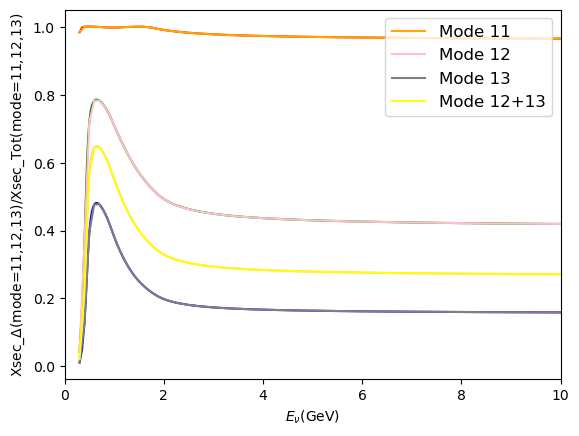

In [26]:
#### splines prepared for event reweighting with arbitrary neutrino energy
import matplotlib.pyplot as plt
results=np.array(read())
modex=results[:,1]
neutrinox=results[:,0]
enx=results[:,2]
mode11x=results[:,3]
mode12x=results[:,4]
mode13x=results[:,5]

tot11=mode11x[(modex==1)]
tot12=mode12x[(modex==1)]
tot13=mode13x[(modex==1)]

tot11delta=mode11x[(modex==2)]
tot12delta=mode12x[(modex==2)]
tot13delta=mode13x[(modex==2)]



enx=enx[modex==1]

plt.plot(enx[3:],tot11delta[3:]/tot11[3:], "red")
plt.plot(enx[3:],tot12delta[3:]/tot12[3:],"green")
plt.plot(enx[3:],tot13delta[3:]/tot13[3:], "blue")
plt.plot(enx[3:],(tot13delta[3:]+tot12delta[3:])/(tot12[3:]+tot13[3:]), color="pink")
bspl1 = make_interp_spline(enx[3:],tot11delta[3:]/tot11[3:])
bspl2 = make_interp_spline(enx[3:],tot12delta[3:]/tot12[3:])
bspl3 = make_interp_spline(enx[3:],tot13delta[3:]/tot13[3:])
bspl4 = make_interp_spline(enx[3:],(tot13delta[3:]+tot12delta[3:])/(tot12[3:]+tot13[3:]))

xx = np.linspace(0.3, 10, 100)

plt.plot(xx,bspl1(xx), "orange", label="Mode 11")
plt.plot(xx,bspl2(xx), "pink",label="Mode 12")
plt.plot(xx,bspl3(xx), "gray",label="Mode 13")
plt.plot(xx,bspl4(xx), "yellow",label="Mode 12+13")
plt.legend(fontsize=12)
enx[2:]
plt.xlim(0,10)
plt.xlabel(r"$E_{\nu}$(GeV)")
plt.ylabel(r"Xsec_$\Delta$(mode=11,12,13)/Xsec_Tot(mode=11,12,13)")

In [27]:
## CC1pi+ (for Q^2 and theta_mu,pi cross-sections) selection for NEUT and GIBUU

# def cc1pi_masks(mode_arr,pdg_arr,Q2_arr,chase_arr,px_arr,py_arr,pz_arr,E_arr,binding):
#     pi_mom_cut=0.2
#     pi_th_cut=0.2
#     final_state=chase_arr==1
#     # pion definitions
#     is_pi_plus  = (pdg_arr == 211) & (np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>pi_mom_cut) & (pz_arr/np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>pi_th_cut)
#     is_pi_minus = (pdg_arr == -211) #& (np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>pi_mom_cut) & (pz_arr/np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>pi_th_cut)
#     is_pi0      = (pdg_arr == 111) #& (np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>pi_mom_cut) & (pz_arr/np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>pi_th_cut)
#     is_proton = (pdg_arr == 2212)  #& (E_arr-binding-0.938 > 0)
#     is_accepteable_lepton=(pdg_arr == 13) & (np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>0.2) & (pz_arr/np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>0.2)
#     # counts per event
#     n_pi_plus  = ak.sum(is_pi_plus & final_state, axis=1)
#     n_pi_minus = ak.sum(is_pi_minus & final_state, axis=1)
#     n_pi0      = ak.sum(is_pi0 & final_state, axis=1)
#     n_proton = ak.sum(is_proton & final_state, axis=1)
#     n_lepton= ak.sum(is_accepteable_lepton & final_state, axis=1)
#     # CC1pi+ mask 
#     mask_cc1pi = (n_pi_plus == 1) & (n_pi_minus == 0) & (n_pi0 == 0) & (n_lepton>0)
#     mask_cc1pi_pi= (is_pi_plus[mask_cc1pi]) & (final_state[mask_cc1pi])
#     mask_cc1pi_mu= (is_accepteable_lepton[mask_cc1pi]) & (final_state[mask_cc1pi])
#     mask_cc1pi_proton= (is_proton[mask_cc1pi]) & (final_state[mask_cc1pi])
    
#     return mask_cc1pi, mask_cc1pi_pi, mask_cc1pi_mu, mask_cc1pi_proton
def cc1pi_masks(pdg_arr, chase_arr, px_arr, py_arr, pz_arr, nupdg_arr=None,
                mu_p_cut=0.2, mu_cos_cut=0.2, pi_p_cut=0.2, pi_cos_cut=0.2):
    fs   = chase_arr == 1
    p    = np.sqrt(px_arr**2 + py_arr**2 + pz_arr**2)
    cos  = pz_arr / p                                  # beam along +z
    apdg = abs(pdg_arr)
    is_pip   = pdg_arr == 211
    is_mu    = pdg_arr == 13
    is_meson = (apdg >= 111) & (apdg <= 557)
    is_lep   = (apdg == 11) | (apdg == 13) | (apdg == 15)
    is_p     = pdg_arr == 2212

    # 1. topology, counted with no phase-space cuts
    topo = ((ak.sum(is_pip & fs, axis=1) == 1) & (ak.sum(is_meson & fs, axis=1) == 1)
            & (ak.sum(is_lep & fs, axis=1) == 1) & (ak.sum(is_mu & fs, axis=1) == 1))
    if nupdg_arr is not None:
        topo = topo & (nupdg_arr == 14)

    # 2. phase-space cuts on that single pi+ and mu-
    pi_ok = ak.any(is_pip & fs & (p > pi_p_cut) & (cos > pi_cos_cut), axis=1)
    mu_ok = ak.any(is_mu  & fs & (p > mu_p_cut) & (cos > mu_cos_cut), axis=1)
    mask = topo & pi_ok & mu_ok

    return mask, (is_pip & fs)[mask], (is_mu & fs)[mask], (is_p & fs)[mask]



# def cc1pi_masks_gibuu(mode_arr3,pdg_arr3,Q2_arr3,charge_arr3,px_arr3,py_arr3,pz_arr3,E_arr3,binding,px_arr3l,py_arr3l,pz_arr3l,E_arr3l):
#     pi_mom_cut=0.2
#     pi_th_cut=0.2   
#     # final state
#     final_state_w_gibuu = (pdg_arr3 == 101)
    
#     # pion definitions
#     is_pi_plus_w_gibuu  = (charge_arr3 == 1) & (np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)>pi_mom_cut) & (pz_arr3/np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)>pi_th_cut)
#     is_pi_minus_w_gibuu = (charge_arr3 == -1) #& (np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)>pi_mom_cut) & (pz_arr3/np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)>pi_th_cut)
#     is_pi0_w_gibuu      = (charge_arr3 == 0)  #& (np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)>pi_mom_cut) & (pz_arr3/np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)>pi_th_cut)
#     is_proton_w_gibuu = (charge_arr3 == 1) #& (pdg_arr3 == 1) & (E_arr3-binding-0.938 > 0)
#     is_acceptable_w_lepton= (np.sqrt(px_arr3l**2+py_arr3l**2+pz_arr3l**2)>0.2) & (pz_arr3l/np.sqrt(px_arr3l**2+py_arr3l**2+pz_arr3l**2)>0.2)
    
#     # counts per event
#     n_pi_plus_w_gibuu  = ak.sum((is_pi_plus_w_gibuu & final_state_w_gibuu), axis=1)
#     n_pi_minus_w_gibuu = ak.sum((is_pi_minus_w_gibuu & final_state_w_gibuu), axis=1)
#     n_pi0_w_gibuu      = ak.sum((is_pi0_w_gibuu & final_state_w_gibuu), axis=1)
#     n_proton_w_gibuu     = ak.sum((is_proton_w_gibuu), axis=1)
    
#     # CC1pi+ mask 
#     mask_cc1pi_w_gibuu = (n_pi_plus_w_gibuu == 1) & (n_pi_minus_w_gibuu == 0) & (n_pi0_w_gibuu == 0) &  (is_acceptable_w_lepton==True)
#     # select only CC1pi+ events
#     mask_cc1pi_pi_w_gibuu= (is_pi_plus_w_gibuu[mask_cc1pi_w_gibuu]) & (final_state_w_gibuu[mask_cc1pi_w_gibuu])
#     mask_cc1pi_proton_w_gibuu= (is_proton_w_gibuu[mask_cc1pi_w_gibuu]) 
    
#     return mask_cc1pi_w_gibuu, mask_cc1pi_pi_w_gibuu, mask_cc1pi_w_gibuu, mask_cc1pi_proton_w_gibuu

def cc1pi_masks_gibuu(pdg_arr, charge_arr, px_arr, py_arr, pz_arr, nupdg_arr=None,
                mu_p_cut=0.2, mu_cos_cut=0.2, pi_p_cut=0.2, pi_cos_cut=0.2):
    chase_arr=ak.ones_like(pdg_arr)
    chase_arr = ak.local_index(pdg_arr, axis=1) != 1
    fs   = chase_arr == 1
    p    = np.sqrt(px_arr**2 + py_arr**2 + pz_arr**2)
    cos  = pz_arr / p                                  # beam along +z
    apdg = abs(pdg_arr)
    is_pip   = (pdg_arr == 101) & (charge_arr==1)
    is_mu    = pdg_arr == 902
    is_meson = (apdg >= 99) & (apdg <= 102)
    is_lep   = (apdg == 901) | (apdg == 902) | (apdg == 903)
    is_p     = (pdg_arr == 1) & (charge_arr==1)

    # 1. topology, counted with no phase-space cuts
    topo = ((ak.sum(is_pip & fs, axis=1) == 1) & (ak.sum(is_meson & fs, axis=1) == 1)
            & (ak.sum(is_lep & fs, axis=1) == 1) & (ak.sum(is_mu & fs, axis=1) == 1))
    if nupdg_arr is not None:
        topo = topo #& (nupdg_arr == 14)

    # 2. phase-space cuts on that single pi+ and mu-
    pi_ok = ak.any(is_pip & fs & (p > pi_p_cut) & (cos > pi_cos_cut), axis=1)
    mu_ok = ak.any(is_mu  & fs & (p > mu_p_cut) & (cos > mu_cos_cut), axis=1)
    mask = topo & pi_ok & mu_ok

    return mask, (is_pip & fs)[mask], (is_mu & fs)[mask], (is_p & fs)[mask]


    
def to3( px, py, pz):
    def _np(a):
        return np.asarray(ak.to_numpy(ak.fill_none(a, np.nan)), dtype=float)
    return np.stack([_np(px), _np(py), _np(pz)], axis=1)    

In [28]:
## reconstructed variables definitions
import numpy as np
import numba as nb
from numba import njit, prange

nb.set_num_threads(4)

@njit(parallel=True, fastmath=True, cache=True)
def _kernel(px_mu, py_mu, pz_mu, px_pi, py_pi, pz_pi,
            m_p, m_mu, m_pi, B, E_nu_rec, Q2_rec):
    for i in prange(px_mu.shape[0]):
        E_mu = np.sqrt(px_mu[i]**2 + py_mu[i]**2 + pz_mu[i]**2 + m_mu**2)
        E_pi = np.sqrt(px_pi[i]**2 + py_pi[i]**2 + pz_pi[i]**2 + m_pi**2)
        costh_mu=pz_mu[i]/(np.sqrt(px_mu[i]**2 + py_mu[i]**2 + pz_mu[i]**2))
        p_mu=np.sqrt(px_mu[i]**2 + py_mu[i]**2 + pz_mu[i]**2)
        px = px_mu[i] + px_pi[i]
        py = py_mu[i] + py_pi[i]
        pz = pz_mu[i] + pz_pi[i]
        pvis2 = px*px + py*py + pz*pz

        A = m_p - B - E_mu - E_pi
        E = (m_p**2 - A**2 + pvis2) / (2.0 * (A + pz))
        
        E_nu_rec[i] = E
        # Q2_rec[i] = 2.0 * E_nu_rec[i] * (E_mu - pz_mu[i]*costh_mu) - m_mu**2
        Q2_rec[i] = -(m_mu**2-2*E_nu_rec[i]*(E_mu-p_mu*costh_mu))
    
def t2k_cc1pip_reco(px_mu, py_mu, pz_mu, px_pi, py_pi, pz_pi,
                    m_p=0.9382720813, m_mu=0.1056583755,
                    m_pi=0.13957039, binding_energy=0.025):
    # constants must be true scalars
    for name, v in dict(m_p=m_p, m_mu=m_mu, m_pi=m_pi,
                        binding_energy=binding_energy).items():
        if np.ndim(v) != 0:
            raise ValueError(f"{name} must be a scalar, got shape {np.shape(v)}")

    arrs = np.broadcast_arrays(*[np.asarray(a, dtype=np.float64)
                                 for a in (px_mu, py_mu, pz_mu, px_pi, py_pi, pz_pi)])
    shape = arrs[0].shape
    flat = [np.ascontiguousarray(a).ravel() for a in arrs]   # all 1D now

    E_nu_rec = np.empty(flat[0].shape, dtype=np.float64)
    Q2_rec = np.empty(flat[0].shape, dtype=np.float64)

    _kernel(*flat, float(m_p), float(m_mu), float(m_pi), float(binding_energy),
            E_nu_rec, Q2_rec)
    return E_nu_rec.reshape(shape), Q2_rec.reshape(shape)

def t2k_cc1pip_reco_gibuu(px_mu, py_mu, pz_mu, px_pi, py_pi, pz_pi,
                    m_p=0.9382720813, m_mu=0.1056583755,
                    m_pi=0.13957039, binding_energy=0.0):
    # constants must be true scalars
    for name, v in dict(m_p=m_p, m_mu=m_mu, m_pi=m_pi,
                        binding_energy=binding_energy).items():
        if np.ndim(v) != 0:
            raise ValueError(f"{name} must be a scalar, got shape {np.shape(v)}")

    arrs = np.broadcast_arrays(*[np.asarray(a, dtype=np.float64)
                                 for a in (px_mu, py_mu, pz_mu, px_pi, py_pi, pz_pi)])
    shape = arrs[0].shape
    flat = [np.ascontiguousarray(a).ravel() for a in arrs]   # all 1D now

    E_nu_rec = np.empty(flat[0].shape, dtype=np.float64)
    Q2_rec = np.empty(flat[0].shape, dtype=np.float64)

    _kernel(*flat, float(m_p), float(m_mu), float(m_pi), float(binding_energy),
            E_nu_rec, Q2_rec)
    return E_nu_rec.reshape(shape), Q2_rec.reshape(shape)

In [29]:
## event selection for NEUT
## CC1PI event selection
pdg_arr   = pdg[idx1]
mode_arr = mode[idx1]
chase_arr = chase[idx1]
E_arr     = E[idx1]
Q2_arr = Q2[idx1]
px_arr = px[idx1]
py_arr= py[idx1]
pz_arr=pz[idx1]
mass_offset=0.025
# proton selection (final state)
# mask_cc1pi_all=cc1pi_masks(mode_arr,pdg_arr,Q2_arr,chase_arr,px_arr,py_arr,pz_arr,E_arr,mass_offset)
mask_cc1pi_all=cc1pi_masks(pdg_arr, chase_arr, px_arr, py_arr, pz_arr)

ppi_for_reco=to3(px_arr[mask_cc1pi_all[0]][mask_cc1pi_all[1]],py_arr[mask_cc1pi_all[0]][mask_cc1pi_all[1]],pz_arr[mask_cc1pi_all[0]][mask_cc1pi_all[1]])
pmu_for_reco=to3(px_arr[mask_cc1pi_all[0]][mask_cc1pi_all[2]],py_arr[mask_cc1pi_all[0]][mask_cc1pi_all[2]],pz_arr[mask_cc1pi_all[0]][mask_cc1pi_all[2]])
beam_dir = np.tile(np.array([0., 0., 1.]), (len(ppi_for_reco), 1))

In [9]:
mask_cc1pi_all

(<Array [False, False, False, ..., False, False, False] type='950082 * bool'>,
 <Array [[False, False, False, False, True], ...] type='67054 * var * bool'>,
 <Array [[False, False, True, False, False], ...] type='67054 * var * bool'>,
 <Array [[False, False, ..., False, False], ...] type='67054 * var * bool'>)

In [30]:
px_mu=np.array(ak.flatten(pmu_for_reco[:,0]))
py_mu=np.array(ak.flatten(pmu_for_reco[:,1]))
pz_mu=np.array(ak.flatten(pmu_for_reco[:,2]))
px_pi=np.array(ak.flatten(ppi_for_reco[:,0]))
py_pi=np.array(ak.flatten(ppi_for_reco[:,1]))
pz_pi=np.array(ak.flatten(ppi_for_reco[:,2]))
output=t2k_cc1pip_reco(px_mu, py_mu, pz_mu, px_pi,py_pi,pz_pi)

In [31]:
pdg_arr3=ID_gibuu_w_med[idx2]
charge_arr3=charge_gibuu_w_med[idx2]
px_arr3=px_gibuu_w_med[idx2]
py_arr3=py_gibuu_w_med[idx2]
pz_arr3=pz_gibuu_w_med[idx2]
# mode_arr3=mode[idx1]*ak.ones_like(pdg_arr3)
# enf_arr3=truenuE[idx1]*ak.ones_like(pdg_arr3)
mass_offfset=0.0
# mask_cc1pi_all_gibuu=cc1pi_masks_gibuu(mode_arr3,pdg_arr3,Q2_arr,charge_arr3,px_arr3,py_arr3,pz_arr3,E_arr3,mass_offset,px_arr3l,py_arr3l,pz_arr3l,E_arr3l)
mask_cc1pi_all_gibuu=cc1pi_masks_gibuu(pdg_arr3, charge_arr3, px_arr3, py_arr3, pz_arr3)
ppi_for_reco_gibuu=to3(px_arr3[mask_cc1pi_all_gibuu[0]][mask_cc1pi_all_gibuu[1]],py_arr3[mask_cc1pi_all_gibuu[0]][mask_cc1pi_all_gibuu[1]],pz_arr3[mask_cc1pi_all_gibuu[0]][mask_cc1pi_all_gibuu[1]])
pmu_for_reco_gibuu=to3(px_arr3[mask_cc1pi_all_gibuu[0]][mask_cc1pi_all_gibuu[2]],py_arr3[mask_cc1pi_all_gibuu[0]][mask_cc1pi_all_gibuu[2]],pz_arr3[mask_cc1pi_all_gibuu[0]][mask_cc1pi_all_gibuu[2]])
beam_dir_gibuu = np.tile(np.array([0., 0., 1.]), (len(ppi_for_reco), 1))

In [32]:
px_mu_gibuu=np.array(ak.flatten(pmu_for_reco_gibuu[:,0]))
py_mu_gibuu=np.array(ak.flatten(pmu_for_reco_gibuu[:,1]))
pz_mu_gibuu=np.array(ak.flatten(pmu_for_reco_gibuu[:,2]))
px_pi_gibuu=np.array(ak.flatten(ppi_for_reco_gibuu[:,0]))
py_pi_gibuu=np.array(ak.flatten(ppi_for_reco_gibuu[:,1]))
pz_pi_gibuu=np.array(ak.flatten(ppi_for_reco_gibuu[:,2]))
output_g=t2k_cc1pip_reco_gibuu(px_mu_gibuu, py_mu_gibuu, pz_mu_gibuu, px_pi_gibuu,py_pi_gibuu,pz_pi_gibuu)

In [33]:
## now only the events on H
mode_h=mode[targetA==1]
pdg_h=pdg[targetA==1]
Q2_h=Q2[targetA==1]
chase_h=chase[targetA==1]
px_h=px[targetA==1]
py_h=py[targetA==1]
pz_h=pz[targetA==1]
E_h=E[targetA==1]
mass_offset=0.00

mask_on_h=cc1pi_masks(pdg_h, chase_h, px_h, py_h, pz_h)
# mask_on_h=cc1pi_masks(mode_h,pdg_h,Q2_h,chase_h,px_h,py_h,pz_h,E_h,mass_offset)

ppi_for_reco_h=to3(px_h[mask_on_h[0]][mask_on_h[1]],py_h[mask_on_h[0]][mask_on_h[1]],pz_h[mask_on_h[0]][mask_on_h[1]])
pmu_for_reco_h=to3(px_h[mask_on_h[0]][mask_on_h[2]],py_h[mask_on_h[0]][mask_on_h[2]],pz_h[mask_on_h[0]][mask_on_h[2]])
beam_dir = np.tile(np.array([0., 0., 1.]), (len(ppi_for_reco), 1))

px_mu_h=np.array(ak.flatten(pmu_for_reco_h[:,0]))
py_mu_h=np.array(ak.flatten(pmu_for_reco_h[:,1]))
pz_mu_h=np.array(ak.flatten(pmu_for_reco_h[:,2]))
px_pi_h=np.array(ak.flatten(ppi_for_reco_h[:,0]))
py_pi_h=np.array(ak.flatten(ppi_for_reco_h[:,1]))
pz_pi_h=np.array(ak.flatten(ppi_for_reco_h[:,2]))
output_h=t2k_cc1pip_reco(px_mu_h, py_mu_h, pz_mu_h, px_pi_h,py_pi_h,pz_pi_h)

/nfs/pic.es/user/p/pdasgupt/.local/lib/python3.14/site-packages/awkward/_nplikes/array_module.py:300: RuntimeWarning: invalid value encountered in divide
  return impl(*broadcasted_args, **(kwargs or {}))


In [14]:
mask_on_h

(<Array [False, False, True, True, ..., True, False, True] type='32670 * bool'>,
 <Array [[False, False, False, False, True], ...] type='12256 * var * bool'>,
 <Array [[False, False, True, False, False], ...] type='12256 * var * bool'>,
 <Array [[False, False, False, True, False], ...] type='12256 * var * bool'>)

In [34]:
### 1H 
bins_array = np.array([0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0,1.2,1.4,1.6,1.8,2.0,3.3])
weightp=np.ones(len(weight))
constant=((len(weight[idx1])+len(weight[targetA==1]))/1e6)**(-1)*weight[idx1][0]### those Q2 within physical range ###

weightp[mode==11]=bspl1(truenuE[mode==11])
weightp[mode==12]=bspl2(truenuE[mode==12])
weightp[mode==13]=bspl3(truenuE[mode==13])

weightp_gibuu=np.ones(len(weight))
weightp_gibuu[mode==11]=bspl1(truenuE[mode==11])
weightp_gibuu[(mode==12)|(mode==13)]=bspl4(truenuE[(mode==12)|(mode==13)])
### those Q2 within physical range ###
############################## NEUT
test_Q2_h=output_h[1]
mode_cc1pi_neut_h=mode_h[mask_on_h[0]]
enf_arr_h=truenuE[targetA==1]*np.ones(len(truenuE[targetA==1]))
enf_cc1pi_neut_h=enf_arr_h[mask_on_h[0]]
diff=(bins_array[1:]-bins_array[:-1])
binc=(bins_array[1:]+bins_array[:-1])*0.5
diff1=np.append(diff,diff[-1])
aa_h=np.histogram(test_Q2_h,bins=bins_array,weights=weightp[targetA==1][mask_on_h[0]]*constant,range=(0,10))
aa_h

(array([1.25940982e-41, 1.60837829e-41, 1.34823546e-41, 8.91866851e-42,
        6.16894279e-42, 3.87077177e-42, 2.73394950e-42, 2.14599948e-42,
        1.82137527e-42, 1.13993924e-42, 1.89431963e-42, 1.47764018e-42,
        9.83532480e-43, 7.73031249e-43, 4.97560993e-43, 1.78602239e-42]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.2, 1.4,
        1.6, 1.8, 2. , 3.3]))

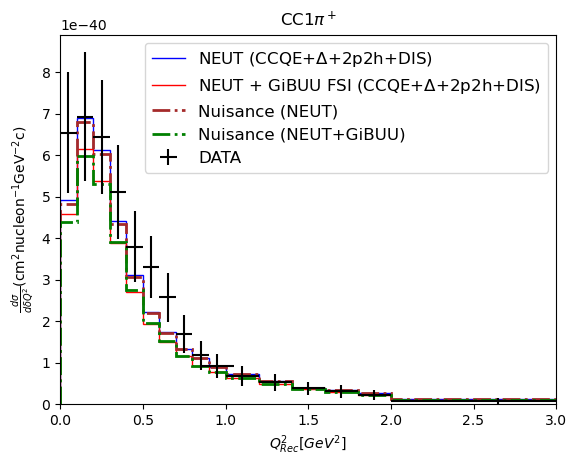

In [16]:
## 12C +1H 
############################## NEUT
test_Q2=output[1]
mode_cc1pi_neut=mode_arr[mask_cc1pi_all[0]]
enf_arr=truenuE[idx1]*np.ones(len(truenuE[idx1]))
enf_cc1pi_neut=enf_arr[mask_cc1pi_all[0]]
yyr,bins1=np.histogram(test_Q2,bins=bins_array,weights=weightp[idx1][mask_cc1pi_all[0]]*constant,range=(0,10))

###################################################################
##########
# plt.stairs((aa[0]+aa_h[0])/diff,aa[1], label="NEUT Reco")
plt.stairs((yyr+aa_h[0])/diff,bins1,color="blue", label=r"NEUT (CCQE+$\Delta$+2p2h+DIS)")   #"label="NEUT Reco reweighted for Res")## 12C+1H
plt.legend(fontsize=14)

################################GiBUU
test_Q2_g=output_g[1]
mode_cc1pi_gibuu=mode_arr[mask_cc1pi_all_gibuu[0]]
enf_arr=truenuE[idx1]*np.ones(len(truenuE[idx1]))
enf_cc1pi_gibuu=enf_arr[mask_cc1pi_all_gibuu[0]]

diff=(bins_array[1:]-bins_array[:-1])
binc=(bins_array[1:]+bins_array[:-1])*0.5
diff1=np.append(diff,diff[-1])
yyr_g,bins=np.histogram(test_Q2_g,bins=bins_array,weights=weightp_gibuu[idx1][mask_cc1pi_all_gibuu[0]]*constant,range=(0,10))
# plt.stairs((aa[0]+aa_h[0])/diff,aa[1], label="GiBUU Reco")
plt.stairs((yyr_g+aa_h[0])/diff,bins1, color="red",label=r"NEUT + GiBUU FSI (CCQE+$\Delta$+2p2h+DIS)")#+ GiBUU Reco reweighted for Res")
plt.legend(fontsize=14)
data=[6.542157e-40,6.927502e-40,6.433097e-40,5.109654e-40,3.797065e-40,3.3118997e-40,2.571753e-40,1.68798e-40,1.176717e-40,9.147285e-41,6.721723e-41,5.30897e-41,3.808583e-41,3.048338e-41,2.238079e-41,7.6276e-42]
xerr=[0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.1,0.1,0.1,0.1,0.1,0.1,0.65]
yerr=[1.464e-40,1.555e-40,1.370e-40,1.126e-40,8.510e-41,7.431e-41,5.983e-41,4.528e-41,3.454e-41,2.953e-41,2.387e-41,2.055e-41,1.598e-41,1.539e-41,1.265e-41,7.5e-42]
plt.errorbar(binc,data,xerr=xerr,yerr=yerr, color="black", fmt='none', label="DATA")
plt.legend(fontsize=14)

file_test=uproot.open("/data/neutrinos/scratch/pingal/nuisance/build/app/test_Q2.root")

plt.stairs(file_test['T2K_CC1pip_CH_XSec_1DQ2_nu_MC'].values(),file_test['T2K_CC1pip_CH_XSec_1DQ2_nu_MC'].axis().edges(),color="brown",ls="-.",lw=2,label="Nuisance (NEUT)")

file_test=uproot.open("/data/neutrinos/scratch/pingal/nuisance/build/app/test_Q2_gibuu.root")

plt.stairs(file_test['T2K_CC1pip_CH_XSec_1DQ2_nu_MC'].values(),file_test['T2K_CC1pip_CH_XSec_1DQ2_nu_MC'].axis().edges(),color="green",ls="-.",lw=2,label="Nuisance (NEUT+GiBUU)")

plt.xlabel(r"$Q_{Rec}^2 [GeV^2]$")
plt.xlim(0,3)
plt.ylabel(r"$\frac{d\sigma}{d\delta Q^2} (\rm cm^{2} nucleon^{-1} GeV^{-2}c)$")
plt.title(r"CC1$\pi^+$")
plt.legend()
plt.legend(fontsize=12)
plt.xlim(0,3)
plt.savefig("CC1pi_Q2_reco.png")


In [17]:
file_test['T2K_CC1pip_CH_XSec_1DQ2_nu_MC'].values()/((yyr+aa_h[0])/diff)

array([0.89227144, 0.86596101, 0.8640063 , 0.88540441, 0.88198579,
       0.87731062, 0.87389741, 0.87014632, 0.82451069, 0.84908881,
       0.85652976, 0.85308084, 0.90450023, 0.84049871, 0.83395997,
       0.81996608])

In [18]:
chase_arr_h = chase[targetA==1]
E_arr_h     = E[targetA==1]
Q2_arr_h = Q2[targetA==1]
px_arr_h = px[targetA==1]
py_arr_h= py[targetA==1]
pz_arr_h= pz[targetA==1]
mode_arr_h=mode[targetA==1]
theta_arr_h=np.arccos((px_arr_h*px_arr_h[:,2]+py_arr_h*py_arr_h[:,2]+pz_arr_h*pz_arr_h[:,2])/(np.sqrt(px_arr_h*px_arr_h+py_arr_h*py_arr_h+pz_arr_h*pz_arr_h)*np.sqrt(px_arr_h[:,2]*px_arr_h[:,2]+py_arr_h[:,2]*py_arr_h[:,2]+pz_arr_h[:,2]*pz_arr_h[:,2])))
#theta_arr=np.arccos(pz_arr/np.sqrt(px_arr*px_arr+py_arr*py_arr+pz_arr*pz_arr))
enf_h=truenuE[targetA==1]*ak.ones_like(pdg[targetA==1])
enf_cc1pi_neut_h=enf_h[mask_on_h[0]][mask_on_h[1]]
theta_cc1pi_neut_h=theta_arr_h[mask_on_h[0]][mask_on_h[1]]
mode_cc1pi_neut_h=mode_arr_h[mask_on_h[0]]
#################### GiBUU w med
bins_array = np.array([0.0000,0.1000,0.2000,0.3000,0.4000,0.5000,0.6000,0.7000,0.8000,0.9000,1.00000,1.200000,1.40000,1.60000,1.80000,2.00000,3.1416000])
diff=(bins_array[1:]-bins_array[:-1])
binc=(bins_array[1:]+bins_array[:-1])*0.5
yy_h=np.histogram(ak.flatten(theta_cc1pi_neut_h),bins=bins_array,weights=weightp[targetA==1][mask_on_h[0]]*constant)

/nfs/pic.es/user/p/pdasgupt/.local/lib/python3.14/site-packages/awkward/_nplikes/array_module.py:300: RuntimeWarning: invalid value encountered in arccos
  return impl(*broadcasted_args, **(kwargs or {}))


In [19]:
weightp[targetA==1][mask_on_h[0]],theta_cc1pi_neut_h

(array([0.99967648, 0.9988874 , 0.99896844, ..., 1.00085015, 0.99926837,
        0.97983985], shape=(12256,)),
 <Array [[0.827], [0.981], [2.06], ..., [1.3], [1]] type='12256 * var * float64'>)

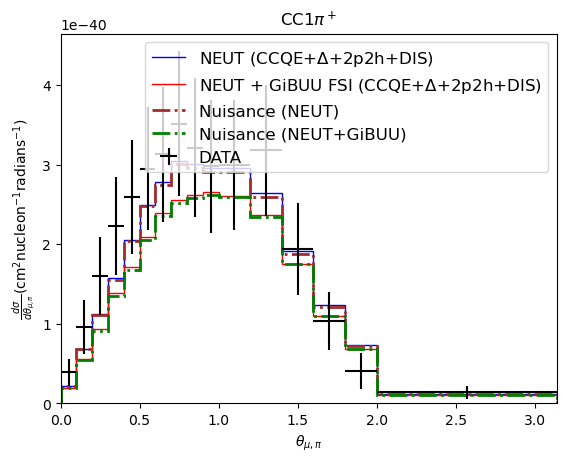

In [20]:
## 12 C+1H
pdg_arr   = pdg[idx1]
chase_arr = chase[idx1]
E_arr     = E[idx1]
Q2_arr = Q2[idx1]
px_arr = px[idx1]
py_arr= py[idx1]
pz_arr= pz[idx1]
theta_arr=np.arccos((px_arr*px_arr[:,2]+py_arr*py_arr[:,2]+pz_arr*pz_arr[:,2])/(np.sqrt(px_arr*px_arr+py_arr*py_arr+pz_arr*pz_arr)*np.sqrt(px_arr[:,2]*px_arr[:,2]+py_arr[:,2]*py_arr[:,2]+pz_arr[:,2]*pz_arr[:,2])))
#theta_arr=np.arccos(pz_arr/np.sqrt(px_arr*px_arr+py_arr*py_arr+pz_arr*pz_arr))
enf=truenuE[idx1]*ak.ones_like(pdg[idx1])
enf_cc1pi_neut=enf[mask_cc1pi_all[0]][mask_cc1pi_all[1]]
theta_cc1pi_neut=theta_arr[mask_cc1pi_all[0]][mask_cc1pi_all[1]]
mode_cc1pi_neut=mode_arr[mask_cc1pi_all[0]]
#################### GiBUU w med
bins_array = np.array([0.0000,0.1000,0.2000,0.3000,0.4000,0.5000,0.6000,0.7000,0.8000,0.9000,1.00000,1.200000,1.40000,1.60000,1.80000,2.00000,3.1416000])
diff=(bins_array[1:]-bins_array[:-1])
binc=(bins_array[1:]+bins_array[:-1])*0.5
yy=np.histogram(ak.flatten(theta_cc1pi_neut),bins=bins_array,weights=weightp[idx1][mask_cc1pi_all[0]]*constant)
plt.stairs((yy[0]+yy_h[0])/diff,bins1,color="blue",label=r"NEUT (CCQE+$\Delta$+2p2h+DIS)")

##################################################################
pdg_arr3   = ID_gibuu_w_med[idx2]
charge_arrw = charge_gibuu_w_med[idx2]
px_arr3 = px_gibuu_w_med[idx2]
py_arr3 = py_gibuu_w_med[idx2]
pz_arr3 = pz_gibuu_w_med[idx2]
E_arr3   = E_gibuu_w_med[idx2]
p_arr3= np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)

theta_arr3=np.arccos((px_arr3*px_arr3[:,0]+py_arr3*py_arr3[:,0]+pz_arr3*pz_arr3[:,0])/(np.sqrt(px_arr3[:,0]*px_arr3[:,0]+py_arr3[:,0]*py_arr3[:,0]+pz_arr3[:,0]*pz_arr3[:,0])*np.sqrt(px_arr3*px_arr3+py_arr3*py_arr3+pz_arr3*pz_arr3)))
enf_cc1pi_gibuu=truenuE[idx1][mask_cc1pi_all_gibuu[0]]
theta_cc1pi_w_gibuu=ak.flatten(theta_arr3[mask_cc1pi_all_gibuu[0]][mask_cc1pi_all_gibuu[1]])
mode_cc1pi_w_gibuu=mode_arr[mask_cc1pi_all_gibuu[0]]

zz=np.histogram(theta_cc1pi_w_gibuu,bins=bins_array,weights=weightp_gibuu[idx1][mask_cc1pi_all_gibuu[0]]*constant)

plt.stairs((zz[0]+yy_h[0])/diff,bins1, color="red",  label=r"NEUT + GiBUU FSI (CCQE+$\Delta$+2p2h+DIS)")

data=np.array([0.0039,
0.0096,
0.0160,
0.0223,
0.0259,
0.0295,
0.0313,
0.0351,
0.0321,
0.0298,
0.0299,
0.0318,
0.0194,
0.0104,
0.0041,
0.0014])*1e-38
xerr=diff/2.
yerr=np.sqrt(np.array([0.00000300,0.00001147,0.00002394,0.00003734,0.00005177,0.00005906,0.00007188,0.00008295,0.00007636,0.00006983,0.00006693,0.00006748,0.00003325,0.00001326,0.00000504,0.00000064]))*1e-38    
plt.errorbar(binc,data,xerr=xerr,yerr=yerr, color="black", fmt='none', label="DATA")
# plt.scatter(binc,data)

file_test=uproot.open("/data/neutrinos/scratch/pingal/nuisance/build/app/test_thmupi.root")

plt.stairs(file_test['T2K_CC1pip_CH_XSec_1Dthmupi_nu_MC'].values(),file_test['T2K_CC1pip_CH_XSec_1Dthmupi_nu_MC'].axis().edges(),color="brown",ls="-.",lw=2,label="Nuisance (NEUT)")

file_test=uproot.open("/data/neutrinos/scratch/pingal/nuisance/build/app/test_thmupi_gibuu.root")

plt.stairs(file_test['T2K_CC1pip_CH_XSec_1Dthmupi_nu_MC'].values(),file_test['T2K_CC1pip_CH_XSec_1Dthmupi_nu_MC'].axis().edges(),color="green",ls="-.",lw=2,label="Nuisance (NEUT+GiBUU)")

plt.xlabel(r"$\theta_{\mu,\pi}$")
plt.xlim(0,3.14)
plt.ylabel(r"$\frac{d\sigma}{d\theta_{\mu,\pi}} (\rm cm^{2} nucleon^{-1} radians^{-1})$")
plt.title(r"CC1$\pi^+$")
plt.legend(fontsize=12)
plt.savefig("CC1pi_theta_mupi.png")


In [68]:
## CC1pi+ (for Q^2 and theta_mu,pi cross-sections) selection for NEUT and GIBUU

# def cc1pi_masks(mode_arr,pdg_arr,Q2_arr,chase_arr,px_arr,py_arr,pz_arr,E_arr,binding):
#     pi_mom_cut=0.2
#     pi_th_cut=0.2
#     final_state=chase_arr==1
#     # pion definitions
#     is_pi_plus  = (pdg_arr == 211) & (np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>pi_mom_cut) & (pz_arr/np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>pi_th_cut)
#     is_pi_minus = (pdg_arr == -211) #& (np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>pi_mom_cut) & (pz_arr/np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>pi_th_cut)
#     is_pi0      = (pdg_arr == 111) #& (np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>pi_mom_cut) & (pz_arr/np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>pi_th_cut)
#     is_proton = (pdg_arr == 2212)  #& (E_arr-binding-0.938 > 0)
#     is_accepteable_lepton=(pdg_arr == 13) & (np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>0.2) & (pz_arr/np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>0.2)
#     # counts per event
#     n_pi_plus  = ak.sum(is_pi_plus & final_state, axis=1)
#     n_pi_minus = ak.sum(is_pi_minus & final_state, axis=1)
#     n_pi0      = ak.sum(is_pi0 & final_state, axis=1)
#     n_proton = ak.sum(is_proton & final_state, axis=1)
#     n_lepton= ak.sum(is_accepteable_lepton & final_state, axis=1)
#     # CC1pi+ mask 
#     mask_cc1pi = (n_pi_plus == 1) & (n_pi_minus == 0) & (n_pi0 == 0) & (n_lepton>0)
#     mask_cc1pi_pi= (is_pi_plus[mask_cc1pi]) & (final_state[mask_cc1pi])
#     mask_cc1pi_mu= (is_accepteable_lepton[mask_cc1pi]) & (final_state[mask_cc1pi])
#     mask_cc1pi_proton= (is_proton[mask_cc1pi]) & (final_state[mask_cc1pi])
    
#     return mask_cc1pi, mask_cc1pi_pi, mask_cc1pi_mu, mask_cc1pi_proton
def cc1pi_masks_mod(pdg_arr, chase_arr, px_arr, py_arr, pz_arr, nupdg_arr=None,
                mu_p_cut=0.2, mu_cos_cut=0.2, pi_p_cut=0.0, pi_cos_cut=0.2):
    fs   = chase_arr == 1
    p    = np.sqrt(px_arr**2 + py_arr**2 + pz_arr**2)
    cos  = pz_arr / p                                  # beam along +z
    apdg = abs(pdg_arr)
    is_pip   = pdg_arr == 211
    is_mu    = pdg_arr == 13
    is_meson = (apdg >= 111) & (apdg <= 557)
    is_lep   = (apdg == 11) | (apdg == 13) | (apdg == 15)
    is_p     = pdg_arr == 2212

    # 1. topology, counted with no phase-space cuts
    topo = ((ak.sum(is_pip & fs, axis=1) == 1) & (ak.sum(is_meson & fs, axis=1) == 1)
            & (ak.sum(is_lep & fs, axis=1) == 1) & (ak.sum(is_mu & fs, axis=1) == 1))
    if nupdg_arr is not None:
        topo = topo & (nupdg_arr == 14)

    # 2. phase-space cuts on that single pi+ and mu-
    pi_ok = ak.any(is_pip & fs & (p > pi_p_cut) & (cos > pi_cos_cut), axis=1)
    mu_ok = ak.any(is_mu  & fs & (p > mu_p_cut) & (cos > mu_cos_cut), axis=1)
    mask = topo & pi_ok & mu_ok

    return mask, (is_pip & fs)[mask], (is_mu & fs)[mask], (is_p & fs)[mask]



# def cc1pi_masks_gibuu(mode_arr3,pdg_arr3,Q2_arr3,charge_arr3,px_arr3,py_arr3,pz_arr3,E_arr3,binding,px_arr3l,py_arr3l,pz_arr3l,E_arr3l):
#     pi_mom_cut=0.2
#     pi_th_cut=0.2   
#     # final state
#     final_state_w_gibuu = (pdg_arr3 == 101)
    
#     # pion definitions
#     is_pi_plus_w_gibuu  = (charge_arr3 == 1) & (np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)>pi_mom_cut) & (pz_arr3/np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)>pi_th_cut)
#     is_pi_minus_w_gibuu = (charge_arr3 == -1) #& (np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)>pi_mom_cut) & (pz_arr3/np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)>pi_th_cut)
#     is_pi0_w_gibuu      = (charge_arr3 == 0)  #& (np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)>pi_mom_cut) & (pz_arr3/np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)>pi_th_cut)
#     is_proton_w_gibuu = (charge_arr3 == 1) #& (pdg_arr3 == 1) & (E_arr3-binding-0.938 > 0)
#     is_acceptable_w_lepton= (np.sqrt(px_arr3l**2+py_arr3l**2+pz_arr3l**2)>0.2) & (pz_arr3l/np.sqrt(px_arr3l**2+py_arr3l**2+pz_arr3l**2)>0.2)
    
#     # counts per event
#     n_pi_plus_w_gibuu  = ak.sum((is_pi_plus_w_gibuu & final_state_w_gibuu), axis=1)
#     n_pi_minus_w_gibuu = ak.sum((is_pi_minus_w_gibuu & final_state_w_gibuu), axis=1)
#     n_pi0_w_gibuu      = ak.sum((is_pi0_w_gibuu & final_state_w_gibuu), axis=1)
#     n_proton_w_gibuu     = ak.sum((is_proton_w_gibuu), axis=1)
    
#     # CC1pi+ mask 
#     mask_cc1pi_w_gibuu = (n_pi_plus_w_gibuu == 1) & (n_pi_minus_w_gibuu == 0) & (n_pi0_w_gibuu == 0) &  (is_acceptable_w_lepton==True)
#     # select only CC1pi+ events
#     mask_cc1pi_pi_w_gibuu= (is_pi_plus_w_gibuu[mask_cc1pi_w_gibuu]) & (final_state_w_gibuu[mask_cc1pi_w_gibuu])
#     mask_cc1pi_proton_w_gibuu= (is_proton_w_gibuu[mask_cc1pi_w_gibuu]) 
    
#     return mask_cc1pi_w_gibuu, mask_cc1pi_pi_w_gibuu, mask_cc1pi_w_gibuu, mask_cc1pi_proton_w_gibuu

def cc1pi_masks_gibuu_mod(pdg_arr, charge_arr, px_arr, py_arr, pz_arr, nupdg_arr=None,
                mu_p_cut=0.2, mu_cos_cut=0.2, pi_p_cut=0.0, pi_cos_cut=0.2):
    chase_arr=ak.ones_like(pdg_arr)
    chase_arr = ak.local_index(pdg_arr, axis=1) != 1
    fs   = chase_arr == 1
    p    = np.sqrt(px_arr**2 + py_arr**2 + pz_arr**2)
    cos  = pz_arr / p                                  # beam along +z
    apdg = abs(pdg_arr)
    is_pip   = (pdg_arr == 101) & (charge_arr==1)
    is_mu    = pdg_arr == 902
    is_meson = (apdg >= 99) & (apdg <= 102)
    is_lep   = (apdg == 901) | (apdg == 902) | (apdg == 903)
    is_p     = (pdg_arr == 1) & (charge_arr==1)

    # 1. topology, counted with no phase-space cuts
    topo = ((ak.sum(is_pip & fs, axis=1) == 1) & (ak.sum(is_meson & fs, axis=1) == 1)
            & (ak.sum(is_lep & fs, axis=1) == 1) & (ak.sum(is_mu & fs, axis=1) == 1))
    if nupdg_arr is not None:
        topo = topo #& (nupdg_arr == 14)

    # 2. phase-space cuts on that single pi+ and mu-
    pi_ok = ak.any(is_pip & fs & (p > pi_p_cut) & (cos > pi_cos_cut), axis=1)
    mu_ok = ak.any(is_mu  & fs & (p > mu_p_cut) & (cos > mu_cos_cut), axis=1)
    mask = topo & pi_ok & mu_ok

    return mask, (is_pip & fs)[mask], (is_mu & fs)[mask], (is_p & fs)[mask]


    
def to3( px, py, pz):
    def _np(a):
        return np.asarray(ak.to_numpy(ak.fill_none(a, np.nan)), dtype=float)
    return np.stack([_np(px), _np(py), _np(pz)], axis=1)    

In [69]:
## 1H
pdg_arr_h   = pdg[targetA==1]
chase_arr_h = chase[targetA==1]
E_arr_h     = E[targetA==1]
Q2_arr_h = Q2[targetA==1]
px_arr_h = px[targetA==1]
py_arr_h= py[targetA==1]
pz_arr_h=pz[targetA==1]
mode_arr_h=mode[targetA==1]
enf_h=truenuE[targetA==1]*np.ones(len(mode[targetA==1]))
p_arr_h=np.sqrt(px_arr_h**2+py_arr_h**2+pz_arr_h**2)
theta_arr_h=np.acos(pz_arr_h/p_arr_h)
mass_offset=0.
mask_cc1pi_mod_h=cc1pi_masks_mod(pdg_arr_h,chase_arr_h,px_arr_h,py_arr_h,pz_arr_h)
p_cc1pi_neut_h=ak.flatten(p_arr_h[mask_cc1pi_mod_h[0]][mask_cc1pi_mod_h[1]])
# mode_cc1pi_neut_h=mode_arr_h[mask_cc1pi_mod_h[0]]
# enf_cc1pi_neut_h=enf_h[mask_cc1pi_mod_h[0]]

bins_array = np.array([0.0000,0.2000,0.3000,0.4000,0.5000,0.6000,0.7000,0.8000,0.9000,1.00000,1.100000,1.20000,1.30000,1.40000,1.60000,2.00000,3.00000,15.00000])
diff=(bins_array[1:]-bins_array[:-1])
binc=(bins_array[1:]+bins_array[:-1])*0.5
yy_ppi_h,bins=np.histogram(np.array(p_cc1pi_neut_h),bins=bins_array, weights=weightp[targetA==1][mask_cc1pi_mod_h[0]]*constant)

In [70]:
p_cc1pi_neut_h[mode_cc1pi_neut_h==11],enf_cc1pi_neut_h[mode_cc1pi_neut_h==11]

(<Array [0.157, 0.267, 0.533, ..., 0.215, 0.36, 0.186] type='12048 * float64'>,
 <Array [[1.14], [1.02], ..., [0.843], [2.88]] type='12048 * var * float64'>)

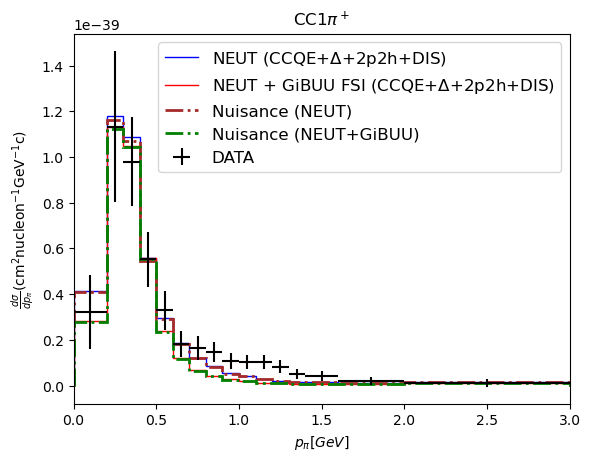

In [71]:
## 12C+1H
pdg_arr   = pdg[idx1]
chase_arr = chase[idx1]
E_arr     = E[idx1]
Q2_arr = Q2[idx1]
px_arr = px[idx1]
py_arr= py[idx1]
pz_arr=pz[idx1]
mode_arr=mode[idx1]
enf=truenuE[idx1]*np.ones(len(mode[idx1]))
p_arr=np.sqrt(px_arr**2+py_arr**2+pz_arr**2)
theta_arr=np.acos(pz_arr/p_arr)
mass_offset=0.035
Ef = E_arr - 0.938 - mass_offset
mask_cc1pi_mod=cc1pi_masks_mod(pdg_arr,chase_arr,px_arr,py_arr,pz_arr)
p_cc1pi_neut=ak.flatten(p_arr[mask_cc1pi_mod[0]][mask_cc1pi_mod[1]])


#################### GiBUU w med
pdg_arr3   = ID_gibuu_w_med[idx2]
charge_arrw = charge_gibuu_w_med[idx2]
px_arr3 = px_gibuu_w_med[idx2]
py_arr3 = py_gibuu_w_med[idx2]
pz_arr3 = pz_gibuu_w_med[idx2]
E_arr3   = E_gibuu_w_med[idx2]
p_arr3= np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)
theta_arr3=np.acos(pz_arr3/p_arr3)
mask_cc1pi_mod_gibuu=cc1pi_masks_gibuu_mod(pdg_arr3,charge_arr3,px_arr3,py_arr3,pz_arr3)

p_cc1pi_w_gibuu=ak.flatten(p_arr3[mask_cc1pi_mod_gibuu[0]][mask_cc1pi_mod_gibuu[1]])

bins_array = np.array([0.0000,0.2000,0.3000,0.4000,0.5000,0.6000,0.7000,0.8000,0.9000,1.00000,1.100000,1.20000,1.30000,1.40000,1.60000,2.00000,3.00000,15.00000])
diff=(bins_array[1:]-bins_array[:-1])
binc=(bins_array[1:]+bins_array[:-1])*0.5

yy,bins=np.histogram(p_cc1pi_neut, bins=bins_array,weights=weightp[idx1][mask_cc1pi_mod[0]]*constant)
plt.stairs((yy+yy_ppi_h)/diff,bins, color="blue", label=r"NEUT (CCQE+$\Delta$+2p2h+DIS)")
zz,bins=np.histogram(p_cc1pi_w_gibuu,bins=bins_array,weights=weightp[idx1][mask_cc1pi_mod_gibuu[0]]*constant)
plt.stairs((zz+yy_ppi_h)/diff,bins, color="red",  label=r"NEUT + GiBUU FSI (CCQE+$\Delta$+2p2h+DIS)")

data=np.array([0.0322,0.1133,0.0979,0.0552,0.0329,0.0182,0.0164,0.0146,0.0107,
               0.0103,0.0102,0.0082,0.0050,0.0043,0.0021,0.0013,0.0001])*1e-38
xerr=diff/2.
yerr=[1.604e-40,3.312e-40,1.951e-40,1.210e-40,8.592e-41,5.746e-41,5.241e-41,4.418e-41,3.409e-41,3.161e-41,3.143e-41,2.776e-41,2.068e-41,2.208e-41,1.746e-41,1.746e-41,7.110e-42]    
plt.errorbar(binc,data,xerr=xerr,yerr=yerr, color="black", fmt='none', label="DATA")
file_test=uproot.open("/data/neutrinos/scratch/pingal/nuisance/build/app/test_ppi.root")

plt.stairs(file_test['T2K_CC1pip_CH_XSec_1Dppi_nu_MC'].values(),file_test['T2K_CC1pip_CH_XSec_1Dppi_nu_MC'].axis().edges(),color="brown",ls="-.",lw=2,label="Nuisance (NEUT)")

file_test=uproot.open("/data/neutrinos/scratch/pingal/nuisance/build/app/test_ppi_gibuu.root")

plt.stairs(file_test['T2K_CC1pip_CH_XSec_1Dppi_nu_MC'].values(),file_test['T2K_CC1pip_CH_XSec_1Dppi_nu_MC'].axis().edges(),color="green",ls="-.",lw=2,label="Nuisance (NEUT+GiBUU)")


# plt.scatter(binc,data)
plt.xlabel(r"$p_\pi [GeV]$")
plt.xlim(0,3)
plt.ylabel(r"$\frac{d\sigma}{dp_\pi} (\rm cm^{2} nucleon^{-1} GeV^{-1}c)$")
plt.title(r"CC1$\pi^+$")
plt.legend(fontsize=12)
plt.savefig("CC1pi_delta_ppi.png")


In [72]:
yy[0],zz[0],yy_ppi_h

(np.float64(7.525326894333611e-41),
 np.float64(4.853502945964866e-41),
 array([7.87851398e-42, 2.97989183e-41, 2.49089692e-41, 1.01345332e-41,
        4.35177674e-42, 2.67501094e-42, 1.50933956e-42, 9.36224231e-43,
        7.28730950e-43, 4.84760834e-43, 2.35961465e-43, 2.48776577e-43,
        1.12083555e-43, 2.97878233e-43, 2.68923603e-43, 3.22565370e-43,
        2.15662274e-43]))

In [73]:
yy

<Array [7.53e-41, 8.83e-41, ..., 1.4e-41, 1.24e-41] type='17 * float64'>

In [74]:
## CC1pi+ (for Q^2 and theta_mu,pi cross-sections) selection for NEUT and GIBUU

# def cc1pi_masks(mode_arr,pdg_arr,Q2_arr,chase_arr,px_arr,py_arr,pz_arr,E_arr,binding):
#     pi_mom_cut=0.2
#     pi_th_cut=0.2
#     final_state=chase_arr==1
#     # pion definitions
#     is_pi_plus  = (pdg_arr == 211) & (np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>pi_mom_cut) & (pz_arr/np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>pi_th_cut)
#     is_pi_minus = (pdg_arr == -211) #& (np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>pi_mom_cut) & (pz_arr/np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>pi_th_cut)
#     is_pi0      = (pdg_arr == 111) #& (np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>pi_mom_cut) & (pz_arr/np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>pi_th_cut)
#     is_proton = (pdg_arr == 2212)  #& (E_arr-binding-0.938 > 0)
#     is_accepteable_lepton=(pdg_arr == 13) & (np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>0.2) & (pz_arr/np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>0.2)
#     # counts per event
#     n_pi_plus  = ak.sum(is_pi_plus & final_state, axis=1)
#     n_pi_minus = ak.sum(is_pi_minus & final_state, axis=1)
#     n_pi0      = ak.sum(is_pi0 & final_state, axis=1)
#     n_proton = ak.sum(is_proton & final_state, axis=1)
#     n_lepton= ak.sum(is_accepteable_lepton & final_state, axis=1)
#     # CC1pi+ mask 
#     mask_cc1pi = (n_pi_plus == 1) & (n_pi_minus == 0) & (n_pi0 == 0) & (n_lepton>0)
#     mask_cc1pi_pi= (is_pi_plus[mask_cc1pi]) & (final_state[mask_cc1pi])
#     mask_cc1pi_mu= (is_accepteable_lepton[mask_cc1pi]) & (final_state[mask_cc1pi])
#     mask_cc1pi_proton= (is_proton[mask_cc1pi]) & (final_state[mask_cc1pi])
    
#     return mask_cc1pi, mask_cc1pi_pi, mask_cc1pi_mu, mask_cc1pi_proton
def cc1pi_masks_mod(pdg_arr, chase_arr, px_arr, py_arr, pz_arr, nupdg_arr=None,
                mu_p_cut=0.2, mu_cos_cut=0.2, pi_p_cut=0.2, pi_cos_cut=0.0):
    fs   = chase_arr == 1
    p    = np.sqrt(px_arr**2 + py_arr**2 + pz_arr**2)
    cos  = pz_arr / p                                  # beam along +z
    apdg = abs(pdg_arr)
    is_pip   = pdg_arr == 211
    is_mu    = pdg_arr == 13
    is_meson = (apdg >= 111) & (apdg <= 557)
    is_lep   = (apdg == 11) | (apdg == 13) | (apdg == 15)
    is_p     = pdg_arr == 2212

    # 1. topology, counted with no phase-space cuts
    topo = ((ak.sum(is_pip & fs, axis=1) == 1) & (ak.sum(is_meson & fs, axis=1) == 1)
            & (ak.sum(is_lep & fs, axis=1) == 1) & (ak.sum(is_mu & fs, axis=1) == 1))
    if nupdg_arr is not None:
        topo = topo & (nupdg_arr == 14)

    # 2. phase-space cuts on that single pi+ and mu-
    pi_ok = ak.any(is_pip & fs & (p > pi_p_cut) & (cos > pi_cos_cut), axis=1)
    mu_ok = ak.any(is_mu  & fs & (p > mu_p_cut) & (cos > mu_cos_cut), axis=1)
    mask = topo & pi_ok & mu_ok

    return mask, (is_pip & fs)[mask], (is_mu & fs)[mask], (is_p & fs)[mask]



# def cc1pi_masks_gibuu(mode_arr3,pdg_arr3,Q2_arr3,charge_arr3,px_arr3,py_arr3,pz_arr3,E_arr3,binding,px_arr3l,py_arr3l,pz_arr3l,E_arr3l):
#     pi_mom_cut=0.2
#     pi_th_cut=0.2   
#     # final state
#     final_state_w_gibuu = (pdg_arr3 == 101)
    
#     # pion definitions
#     is_pi_plus_w_gibuu  = (charge_arr3 == 1) & (np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)>pi_mom_cut) & (pz_arr3/np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)>pi_th_cut)
#     is_pi_minus_w_gibuu = (charge_arr3 == -1) #& (np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)>pi_mom_cut) & (pz_arr3/np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)>pi_th_cut)
#     is_pi0_w_gibuu      = (charge_arr3 == 0)  #& (np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)>pi_mom_cut) & (pz_arr3/np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)>pi_th_cut)
#     is_proton_w_gibuu = (charge_arr3 == 1) #& (pdg_arr3 == 1) & (E_arr3-binding-0.938 > 0)
#     is_acceptable_w_lepton= (np.sqrt(px_arr3l**2+py_arr3l**2+pz_arr3l**2)>0.2) & (pz_arr3l/np.sqrt(px_arr3l**2+py_arr3l**2+pz_arr3l**2)>0.2)
    
#     # counts per event
#     n_pi_plus_w_gibuu  = ak.sum((is_pi_plus_w_gibuu & final_state_w_gibuu), axis=1)
#     n_pi_minus_w_gibuu = ak.sum((is_pi_minus_w_gibuu & final_state_w_gibuu), axis=1)
#     n_pi0_w_gibuu      = ak.sum((is_pi0_w_gibuu & final_state_w_gibuu), axis=1)
#     n_proton_w_gibuu     = ak.sum((is_proton_w_gibuu), axis=1)
    
#     # CC1pi+ mask 
#     mask_cc1pi_w_gibuu = (n_pi_plus_w_gibuu == 1) & (n_pi_minus_w_gibuu == 0) & (n_pi0_w_gibuu == 0) &  (is_acceptable_w_lepton==True)
#     # select only CC1pi+ events
#     mask_cc1pi_pi_w_gibuu= (is_pi_plus_w_gibuu[mask_cc1pi_w_gibuu]) & (final_state_w_gibuu[mask_cc1pi_w_gibuu])
#     mask_cc1pi_proton_w_gibuu= (is_proton_w_gibuu[mask_cc1pi_w_gibuu]) 
    
#     return mask_cc1pi_w_gibuu, mask_cc1pi_pi_w_gibuu, mask_cc1pi_w_gibuu, mask_cc1pi_proton_w_gibuu

def cc1pi_masks_gibuu_mod(pdg_arr, charge_arr, px_arr, py_arr, pz_arr, nupdg_arr=None,
                mu_p_cut=0.2, mu_cos_cut=0.2, pi_p_cut=0.2, pi_cos_cut=0.0):
    chase_arr=ak.ones_like(pdg_arr)
    chase_arr = ak.local_index(pdg_arr, axis=1) != 1
    fs   = chase_arr == 1
    p    = np.sqrt(px_arr**2 + py_arr**2 + pz_arr**2)
    cos  = pz_arr / p                                  # beam along +z
    apdg = abs(pdg_arr)
    is_pip   = (pdg_arr == 101) & (charge_arr==1)
    is_mu    = pdg_arr == 902
    is_meson = (apdg >= 99) & (apdg <= 102)
    is_lep   = (apdg == 901) | (apdg == 902) | (apdg == 903)
    is_p     = (pdg_arr == 1) & (charge_arr==1)

    # 1. topology, counted with no phase-space cuts
    topo = ((ak.sum(is_pip & fs, axis=1) == 1) & (ak.sum(is_meson & fs, axis=1) == 1)
            & (ak.sum(is_lep & fs, axis=1) == 1) & (ak.sum(is_mu & fs, axis=1) == 1))
    if nupdg_arr is not None:
        topo = topo #& (nupdg_arr == 14)

    # 2. phase-space cuts on that single pi+ and mu-
    pi_ok = ak.any(is_pip & fs & (p > pi_p_cut) & (cos > pi_cos_cut), axis=1)
    mu_ok = ak.any(is_mu  & fs & (p > mu_p_cut) & (cos > mu_cos_cut), axis=1)
    mask = topo & pi_ok & mu_ok

    return mask, (is_pip & fs)[mask], (is_mu & fs)[mask], (is_p & fs)[mask]


    
def to3( px, py, pz):
    def _np(a):
        return np.asarray(ak.to_numpy(ak.fill_none(a, np.nan)), dtype=float)
    return np.stack([_np(px), _np(py), _np(pz)], axis=1)    

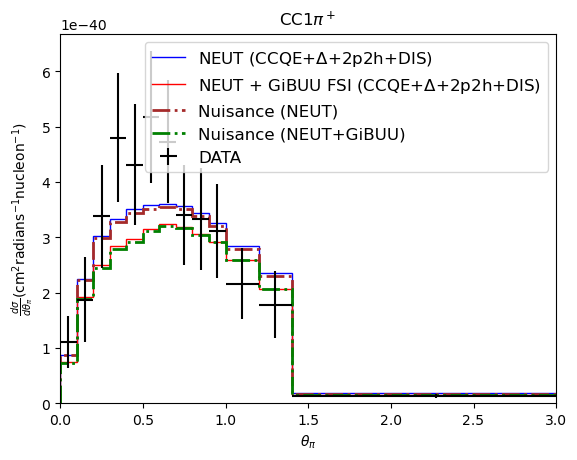

In [75]:
bins_array = np.array([0.0000,0.1000,0.2000,0.3000,0.4000,0.5000,0.6000,0.7000,0.8000,0.9000,1.000,1.2000,1.4000,3.1416000])

## 1H
pdg_arr_h   = pdg[targetA==1]
chase_arr_h = chase[targetA==1]
E_arr_h     = E[targetA==1]
Q2_arr_h = Q2[targetA==1]
px_arr_h = px[targetA==1]
py_arr_h= py[targetA==1]
pz_arr_h=pz[targetA==1]
mode_arr_h=mode[targetA==1]
enf_h=truenuE[targetA==1]*np.ones(len(mode[targetA==1]))
p_arr_h=np.sqrt(px_arr_h**2+py_arr_h**2+pz_arr_h**2)
theta_arr_h=np.acos(pz_arr_h/p_arr_h)
mass_offset=0.
mask_cc1pi_mod_h=cc1pi_masks_mod(pdg_arr_h,chase_arr_h,px_arr_h,py_arr_h,pz_arr_h)
theta_cc1pi_neut_h=ak.flatten(theta_arr_h[mask_cc1pi_mod_h[0]][mask_cc1pi_mod_h[1]])
# mode_cc1pi_neut_h=mode_arr_h[mask_cc1pi_mod_h[0]]
# enf_cc1pi_neut_h=enf_h[mask_cc1pi_mod_h[0]]

diff=(bins_array[1:]-bins_array[:-1])
binc=(bins_array[1:]+bins_array[:-1])*0.5

# hist1_h,bins1=np.histogram(p_cc1pi_neut_h[mode_cc1pi_neut_h==1], bins=bins_array)
# hist2_h,bins1=np.histogram(p_cc1pi_neut_h[mode_cc1pi_neut_h==2], bins=bins_array)
# hist3_h,bins1=np.histogram(p_cc1pi_neut_h[mode_cc1pi_neut_h==26], bins=bins_array)

# hist4_h,bins1=np.histogram(p_cc1pi_neut_h[mode_cc1pi_neut_h==11], weights=bspl1(enf_cc1pi_neut_h[mode_cc1pi_neut_h==11]), bins=bins_array)
# hist5_h,bins1=np.histogram(p_cc1pi_neut_h[mode_cc1pi_neut_h==12], weights=bspl2(enf_cc1pi_neut_h[mode_cc1pi_neut_h==12]),bins=bins_array)
# hist6_h,bins1=np.histogram(p_cc1pi_neut_h[mode_cc1pi_neut_h==13], weights=bspl3(enf_cc1pi_neut_h[mode_cc1pi_neut_h==13]),bins=bins_array)
# yy_ppi_h=(hist1_h+hist2_h+hist3_h+hist4_h+hist5_h+hist6_h)*(weight[targetA==1][0])
yy_thetapi_h,bins=np.histogram(np.array(theta_cc1pi_neut_h),bins=bins_array, weights=weightp[targetA==1][mask_cc1pi_mod_h[0]]*constant)





## 12C+1H
pdg_arr   = pdg[idx1]
chase_arr = chase[idx1]
E_arr     = E[idx1]
Q2_arr = Q2[idx1]
px_arr = px[idx1]
py_arr= py[idx1]
pz_arr=pz[idx1]
mode_arr=mode[idx1]
enf=truenuE[idx1]*np.ones(len(mode[idx1]))
p_arr=np.sqrt(px_arr**2+py_arr**2+pz_arr**2)
theta_arr=np.acos(pz_arr/p_arr)
mass_offset=0.035
Ef = E_arr - 0.938 - mass_offset
mask_cc1pi_mod=cc1pi_masks_mod(pdg_arr,chase_arr,px_arr,py_arr,pz_arr)
theta_cc1pi_neut=ak.flatten(theta_arr[mask_cc1pi_mod[0]][mask_cc1pi_mod[1]])


#################### GiBUU w med
pdg_arr3   = ID_gibuu_w_med[idx2]
charge_arrw = charge_gibuu_w_med[idx2]
px_arr3 = px_gibuu_w_med[idx2]
py_arr3 = py_gibuu_w_med[idx2]
pz_arr3 = pz_gibuu_w_med[idx2]
E_arr3   = E_gibuu_w_med[idx2]
p_arr3= np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)
theta_arr3=np.acos(pz_arr3/p_arr3)
mask_cc1pi_mod_gibuu=cc1pi_masks_gibuu_mod(pdg_arr3,charge_arr3,px_arr3,py_arr3,pz_arr3)

theta_cc1pi_w_gibuu=ak.flatten(theta_arr3[mask_cc1pi_mod_gibuu[0]][mask_cc1pi_mod_gibuu[1]])

diff=(bins_array[1:]-bins_array[:-1])
binc=(bins_array[1:]+bins_array[:-1])*0.5

yy,bins=np.histogram(theta_cc1pi_neut, bins=bins_array,weights=weightp[idx1][mask_cc1pi_mod[0]]*constant)
# plt.step(bins1,np.append(yy/diff,yy[-1]), where="post",  label="NEUT reweighted for Res")
plt.stairs((yy+yy_thetapi_h)/diff,bins, color="blue", label=r"NEUT (CCQE+$\Delta$+2p2h+DIS)")
zz,bins=np.histogram(theta_cc1pi_w_gibuu,bins=bins_array,weights=weightp[idx1][mask_cc1pi_mod_gibuu[0]]*constant)
# plt.step(bins1,np.append(zz/diff,zz[-1]), color="pink", where="post",  label="GiBUU reweighted for Res")
plt.stairs((zz+yy_thetapi_h)/diff,bins, color="red",  label=r"NEUT + GiBUU FSI (CCQE+$\Delta$+2p2h+DIS)")


data_phi=np.array([0.0111,0.0187,0.0338,0.0480,0.0431,0.0517,0.0473,0.0340,0.0333,0.0312,0.0216,0.0178,0.0013])*10**-38
xerr=diff/2.
yerr=np.sqrt(np.array([0.00002172,0.00005862,0.00008754,0.00013540,0.00011936,0.00014181,0.00012355,0.00008216,0.00008376,0.00007216,0.00004131,0.00003700,0.00000016]))*10**-38
plt.errorbar(binc,data_phi,xerr=xerr,yerr=yerr, color="black", fmt='none', label="DATA")

file_test=uproot.open("/data/neutrinos/scratch/pingal/nuisance/build/app/test_thpi.root")

plt.stairs(file_test['T2K_CC1pip_CH_XSec_1Dthpi_nu_MC'].values(),file_test['T2K_CC1pip_CH_XSec_1Dthpi_nu_MC'].axis().edges(),color="brown",ls="-.",lw=2,label="Nuisance (NEUT)")

file_test=uproot.open("/data/neutrinos/scratch/pingal/nuisance/build/app/test_thpi_gibuu.root")

plt.stairs(file_test['T2K_CC1pip_CH_XSec_1Dthpi_nu_MC'].values(),file_test['T2K_CC1pip_CH_XSec_1Dthpi_nu_MC'].axis().edges(),color="green",ls="-.",lw=2,label="Nuisance (NEUT+GiBUU)")




plt.xlim(0,3)
plt.xlabel(r"$\theta_\pi$")
plt.xlim(0,3)
plt.ylabel(r"$\frac{d\sigma}{d\theta_\pi} (\rm cm^{2} radians^{-1}nucleon^{-1})$")
plt.title(r"CC1$\pi^+$")
plt.legend(fontsize=12)
plt.savefig("CC1pi_theta_phi.png")





In [76]:
len(data_phi),len(yerr),len(bins_array)

(13, 13, 14)

In [77]:
theta_cc1pi_neut,mode_cc1pi_neut

(<Array [0.122, 0.828, 0.18, ..., 0.867, 0.97, 0.575] type='73123 * float64'>,
 <Array [13, 13, 11, 11, 11, 11, ..., 11, 13, 11, 13, 26] type='67054 * int32'>)

In [78]:
## relativistic boost
def boost(E, p, beta):
    b2 = np.sum(beta**2, axis=1)
    gamma =  1.0 / np.sqrt(1.0 - b2) 
    bp = np.sum(beta * p, axis=1)
    E_new = gamma * (E - bp)
    safe_b2 = np.where(b2 > 0, b2, 1.0)
    coef = np.where(b2 > 0, (gamma - 1.0) / safe_b2, 0.0) * bp - gamma * E
    p_new = p + coef[:, None] * beta
    return E_new, p_new

def rotate_vectors(vectors, angle, axis):
    """
    Rotate N vectors by N angles around N axes.

    vectors : (3, N)
        vectors[:, i] = vector for event i

    angle : (N,)
        angle[i] = rotation angle for event i, in radians

    axis : (3, N)
        axis[:, i] = rotation axis for event i

    Returns
    -------
    rotated : (3, N)
    """

    vectors = np.asarray(vectors, dtype=float)
    angle = np.asarray(angle, dtype=float)
    axis = np.asarray(axis, dtype=float)

    # Normalize each axis independently
    axis_norm = np.linalg.norm(axis, axis=0)
    axis_hat = axis / axis_norm[None, :]

    ax = axis_hat[0]
    ay = axis_hat[1]
    az = axis_hat[2]

    c = np.cos(angle)
    s = np.sin(angle)
    C = 1.0 - c

    # Rodrigues rotation matrix for every event
    R = np.empty((3, 3, vectors.shape[1]))

    R[0, 0] = c + ax * ax * C
    R[0, 1] = ax * ay * C - az * s
    R[0, 2] = ax * az * C + ay * s

    R[1, 0] = ay * ax * C + az * s
    R[1, 1] = c + ay * ay * C
    R[1, 2] = ay * az * C - ax * s

    R[2, 0] = az * ax * C - ay * s
    R[2, 1] = az * ay * C + ax * s
    R[2, 2] = c + az * az * C

    # Apply each event's rotation matrix to its vector
    rotated = np.einsum('ijk,jk->ik', R, vectors)

    return rotated 
def unit(v):
    return v/np.linalg.norm(v,axis=0)


def vel(E,p):
    return np.array([p[:,0]/E,p[:,1]/E,p[:,2]/E])


In [79]:
## CC1pi+ (for Q^2 and theta_mu,pi cross-sections) selection for NEUT and GIBUU

# def cc1pi_masks(mode_arr,pdg_arr,Q2_arr,chase_arr,px_arr,py_arr,pz_arr,E_arr,binding):
#     pi_mom_cut=0.2
#     pi_th_cut=0.2
#     final_state=chase_arr==1
#     # pion definitions
#     is_pi_plus  = (pdg_arr == 211) & (np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>pi_mom_cut) & (pz_arr/np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>pi_th_cut)
#     is_pi_minus = (pdg_arr == -211) #& (np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>pi_mom_cut) & (pz_arr/np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>pi_th_cut)
#     is_pi0      = (pdg_arr == 111) #& (np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>pi_mom_cut) & (pz_arr/np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>pi_th_cut)
#     is_proton = (pdg_arr == 2212)  #& (E_arr-binding-0.938 > 0)
#     is_accepteable_lepton=(pdg_arr == 13) & (np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>0.2) & (pz_arr/np.sqrt(px_arr**2+py_arr**2+pz_arr**2)>0.2)
#     # counts per event
#     n_pi_plus  = ak.sum(is_pi_plus & final_state, axis=1)
#     n_pi_minus = ak.sum(is_pi_minus & final_state, axis=1)
#     n_pi0      = ak.sum(is_pi0 & final_state, axis=1)
#     n_proton = ak.sum(is_proton & final_state, axis=1)
#     n_lepton= ak.sum(is_accepteable_lepton & final_state, axis=1)
#     # CC1pi+ mask 
#     mask_cc1pi = (n_pi_plus == 1) & (n_pi_minus == 0) & (n_pi0 == 0) & (n_lepton>0)
#     mask_cc1pi_pi= (is_pi_plus[mask_cc1pi]) & (final_state[mask_cc1pi])
#     mask_cc1pi_mu= (is_accepteable_lepton[mask_cc1pi]) & (final_state[mask_cc1pi])
#     mask_cc1pi_proton= (is_proton[mask_cc1pi]) & (final_state[mask_cc1pi])
    
#     return mask_cc1pi, mask_cc1pi_pi, mask_cc1pi_mu, mask_cc1pi_proton
def cc1pi_masks_mod(pdg_arr, chase_arr, px_arr, py_arr, pz_arr, nupdg_arr=None,
                mu_p_cut=0.2, mu_cos_cut=0.2, pi_p_cut=0.2, pi_cos_cut=0.2):
    fs   = chase_arr == 1
    p    = np.sqrt(px_arr**2 + py_arr**2 + pz_arr**2)
    cos  = pz_arr / p                                  # beam along +z
    apdg = abs(pdg_arr)
    is_pip   = pdg_arr == 211
    is_mu    = pdg_arr == 13
    is_meson = (apdg >= 111) & (apdg <= 557)
    is_lep   = (apdg == 11) | (apdg == 13) | (apdg == 15)
    is_p     = pdg_arr == 2212

    # 1. topology, counted with no phase-space cuts
    topo = ((ak.sum(is_pip & fs, axis=1) == 1) & (ak.sum(is_meson & fs, axis=1) == 1)
            & (ak.sum(is_lep & fs, axis=1) == 1) & (ak.sum(is_mu & fs, axis=1) == 1))
    if nupdg_arr is not None:
        topo = topo & (nupdg_arr == 14)

    # 2. phase-space cuts on that single pi+ and mu-
    pi_ok = ak.any(is_pip & fs & (p > pi_p_cut) & (cos > pi_cos_cut), axis=1)
    mu_ok = ak.any(is_mu  & fs & (p > mu_p_cut) & (cos > mu_cos_cut), axis=1)
    mask = topo & pi_ok & mu_ok

    return mask, (is_pip & fs)[mask], (is_mu & fs)[mask], (is_p & fs)[mask]



# def cc1pi_masks_gibuu(mode_arr3,pdg_arr3,Q2_arr3,charge_arr3,px_arr3,py_arr3,pz_arr3,E_arr3,binding,px_arr3l,py_arr3l,pz_arr3l,E_arr3l):
#     pi_mom_cut=0.2
#     pi_th_cut=0.2   
#     # final state
#     final_state_w_gibuu = (pdg_arr3 == 101)
    
#     # pion definitions
#     is_pi_plus_w_gibuu  = (charge_arr3 == 1) & (np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)>pi_mom_cut) & (pz_arr3/np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)>pi_th_cut)
#     is_pi_minus_w_gibuu = (charge_arr3 == -1) #& (np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)>pi_mom_cut) & (pz_arr3/np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)>pi_th_cut)
#     is_pi0_w_gibuu      = (charge_arr3 == 0)  #& (np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)>pi_mom_cut) & (pz_arr3/np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)>pi_th_cut)
#     is_proton_w_gibuu = (charge_arr3 == 1) #& (pdg_arr3 == 1) & (E_arr3-binding-0.938 > 0)
#     is_acceptable_w_lepton= (np.sqrt(px_arr3l**2+py_arr3l**2+pz_arr3l**2)>0.2) & (pz_arr3l/np.sqrt(px_arr3l**2+py_arr3l**2+pz_arr3l**2)>0.2)
    
#     # counts per event
#     n_pi_plus_w_gibuu  = ak.sum((is_pi_plus_w_gibuu & final_state_w_gibuu), axis=1)
#     n_pi_minus_w_gibuu = ak.sum((is_pi_minus_w_gibuu & final_state_w_gibuu), axis=1)
#     n_pi0_w_gibuu      = ak.sum((is_pi0_w_gibuu & final_state_w_gibuu), axis=1)
#     n_proton_w_gibuu     = ak.sum((is_proton_w_gibuu), axis=1)
    
#     # CC1pi+ mask 
#     mask_cc1pi_w_gibuu = (n_pi_plus_w_gibuu == 1) & (n_pi_minus_w_gibuu == 0) & (n_pi0_w_gibuu == 0) &  (is_acceptable_w_lepton==True)
#     # select only CC1pi+ events
#     mask_cc1pi_pi_w_gibuu= (is_pi_plus_w_gibuu[mask_cc1pi_w_gibuu]) & (final_state_w_gibuu[mask_cc1pi_w_gibuu])
#     mask_cc1pi_proton_w_gibuu= (is_proton_w_gibuu[mask_cc1pi_w_gibuu]) 
    
#     return mask_cc1pi_w_gibuu, mask_cc1pi_pi_w_gibuu, mask_cc1pi_w_gibuu, mask_cc1pi_proton_w_gibuu

def cc1pi_masks_gibuu_mod(pdg_arr, charge_arr, px_arr, py_arr, pz_arr, nupdg_arr=None,
                mu_p_cut=0.2, mu_cos_cut=0.2, pi_p_cut=0.2, pi_cos_cut=0.2):
    chase_arr=ak.ones_like(pdg_arr)
    chase_arr = ak.local_index(pdg_arr, axis=1) != 1
    fs   = chase_arr == 1
    p    = np.sqrt(px_arr**2 + py_arr**2 + pz_arr**2)
    cos  = pz_arr / p                                  # beam along +z
    apdg = abs(pdg_arr)
    is_pip   = (pdg_arr == 101) & (charge_arr==1)
    is_mu    = pdg_arr == 902
    is_meson = (apdg >= 99) & (apdg <= 102)
    is_lep   = (apdg == 901) | (apdg == 902) | (apdg == 903)
    is_p     = (pdg_arr == 1) & (charge_arr==1)

    # 1. topology, counted with no phase-space cuts
    topo = ((ak.sum(is_pip & fs, axis=1) == 1) & (ak.sum(is_meson & fs, axis=1) == 1)
            & (ak.sum(is_lep & fs, axis=1) == 1) & (ak.sum(is_mu & fs, axis=1) == 1))
    if nupdg_arr is not None:
        topo = topo #& (nupdg_arr == 14)

    # 2. phase-space cuts on that single pi+ and mu-
    pi_ok = ak.any(is_pip & fs & (p > pi_p_cut) & (cos > pi_cos_cut), axis=1)
    mu_ok = ak.any(is_mu  & fs & (p > mu_p_cut) & (cos > mu_cos_cut), axis=1)
    mask = topo & pi_ok & mu_ok

    return mask, (is_pip & fs)[mask], (is_mu & fs)[mask], (is_p & fs)[mask]


    
def to3( px, py, pz):
    def _np(a):
        return np.asarray(ak.to_numpy(ak.fill_none(a, np.nan)), dtype=float)
    return np.stack([_np(px), _np(py), _np(pz)], axis=1)    

In [80]:
import numpy as np
import awkward as ak

# ---------------------------------------------------------------- helpers
def to3(x, y, z):
    """Stack components into an (N, 3) float array."""
    return np.stack([np.asarray(x), np.asarray(y), np.asarray(z)], axis=1).astype(float)

def boost_to_frame(E, p, beta):
    """Equivalent to ROOT's v.Boost(-beta): go INTO the frame moving with velocity beta.
    E: (N,), p: (N,3), beta: (N,3)"""
    b2    = np.sum(beta**2, axis=1)
    gamma = 1.0 / np.sqrt(1.0 - b2)
    bp    = np.sum(beta * p, axis=1)
    g2    = np.where(b2 > 0, (gamma - 1.0) / np.where(b2 > 0, b2, 1.0), 0.0)
    E_new = gamma * (E - bp)
    p_new = p + ((g2 * bp - gamma * E)[:, None]) * beta
    return E_new, p_new

def rotate(v, angle, axis):
    """Right-handed (active) rotation of v by angle about axis, like TRotation::Rotate.
    v, axis: (N,3); angle: (N,)"""
    k = axis / np.linalg.norm(axis, axis=1, keepdims=True)
    c = np.cos(angle)[:, None]
    s = np.sin(angle)[:, None]
    return v * c + np.cross(k, v) * s + k * np.sum(k * v, axis=1, keepdims=True) * (1.0 - c)

# ---------------------------------------------------------------- inputs

def one_per_event(arr, m):
    sel = arr[m0][m]
    assert ak.all(ak.num(sel) == 1), "mask selects != 1 particle in some events"
    return ak.to_numpy(ak.flatten(sel))


In [81]:
weightp=np.ones(len(weight))
constant=((len(weight[idx])+len(weight[targetA==1]))/1e6)**(-1)*weight[idx1][0]### those Q2 within physical range ###

weightp[mode==11]=bspl1(truenuE[mode==11])
weightp[mode==12]=bspl2(truenuE[mode==12])
weightp[mode==13]=bspl3(truenuE[mode==13])

weightp_gibuu=np.ones(len(weight))
weightp_gibuu[mode==11]=bspl1(truenuE[mode==11])
weightp_gibuu[(mode==12)|(mode==13)]=bspl4(truenuE[(mode==12)|(mode==13)])

In [82]:
## 1H
pdg_arr_h   = pdg[targetA==1]
chase_arr_h = chase[targetA==1]
E_arr_h     = E[targetA==1]
Q2_arr_h = Q2[targetA==1]
px_arr_h = px[targetA==1]
py_arr_h= py[targetA==1]
pz_arr_h=pz[targetA==1]
mode_arr_h=mode[targetA==1]
enf_h=truenuE[targetA==1]*np.ones(len(mode[targetA==1]))
p_arr_h=np.sqrt(px_arr_h**2+py_arr_h**2+pz_arr_h**2)
theta_arr_h=np.acos(pz_arr_h/p_arr_h)
mass_offset=0.
mask_cc1pi1p_mod_h=cc1pi_masks_mod(pdg_arr_h, chase_arr_h, px_arr_h, py_arr_h, pz_arr_h)
m0, m_pi, m_mu = mask_cc1pi1p_mod_h[0], mask_cc1pi1p_mod_h[1], mask_cc1pi1p_mod_h[2]

px_pi=ak.flatten(px_arr_h[mask_cc1pi1p_mod_h[0]][mask_cc1pi1p_mod_h[1]])
py_pi=ak.flatten(py_arr_h[mask_cc1pi1p_mod_h[0]][mask_cc1pi1p_mod_h[1]])
pz_pi=ak.flatten(pz_arr_h[mask_cc1pi1p_mod_h[0]][mask_cc1pi1p_mod_h[1]])
E_pi=ak.flatten(E_arr_h[mask_cc1pi1p_mod_h[0]][mask_cc1pi1p_mod_h[1]])
p_pi = np.array([px_pi,py_pi,pz_pi]).T

px_mu=ak.flatten(px_arr_h[mask_cc1pi1p_mod_h[0]][mask_cc1pi1p_mod_h[2]])
py_mu=ak.flatten(py_arr_h[mask_cc1pi1p_mod_h[0]][mask_cc1pi1p_mod_h[2]])
pz_mu=ak.flatten(pz_arr_h[mask_cc1pi1p_mod_h[0]][mask_cc1pi1p_mod_h[2]])
E_mu=ak.flatten(E_arr_h[mask_cc1pi1p_mod_h[0]][mask_cc1pi1p_mod_h[2]])
p_mu = np.array([px_mu,py_mu,pz_mu]).T

px_nu=px_arr_h[mask_cc1pi1p_mod_h[0]][:,0]
py_nu=py_arr_h[mask_cc1pi1p_mod_h[0]][:,0]
pz_nu=pz_arr_h[mask_cc1pi1p_mod_h[0]][:,0]
E_nu=E_arr_h[mask_cc1pi1p_mod_h[0]][:,0]
p_nu= np.array([px_nu,py_nu,pz_nu]).T


px_N=px_arr_h[mask_cc1pi1p_mod_h[0]][:,1]
py_N=py_arr_h[mask_cc1pi1p_mod_h[0]][:,1]
pz_N=pz_arr_h[mask_cc1pi1p_mod_h[0]][:,1]
E_N=np.sqrt(px_N**2+py_N**2+pz_N**2+0.938**2)
p_N=np.array([px_N,py_N,pz_N]).T

# E_pi = one_per_event(E_arr, m_pi)
# p_pi = to3(one_per_event(px_arr, m_pi), one_per_event(py_arr, m_pi), one_per_event(pz_arr, m_pi))
# E_mu = one_per_event(E_arr, m_mu)
# p_mu = to3(one_per_event(px_arr, m_mu), one_per_event(py_arr, m_mu), one_per_event(pz_arr, m_mu))

# # neutrino (index 0) and target nucleon (index 1)
# E_nu = ak.to_numpy(E_arr[m0][:, 0])
# p_nu = to3(px_arr[m0][:, 0], py_arr[m0][:, 0], pz_arr[m0][:, 0])
# p_N  = to3(px_arr[m0][:, 1], py_arr[m0][:, 1], pz_arr[m0][:, 1])
# E_N  = ak.to_numpy(E_arr[m0][:, 1])                 # stored energy -> matches ROOT's v_target_nucleon
# # E_N = np.sqrt(np.sum(p_N**2, axis=1) + 0.938**2)  # use this instead only if ROOT's nucleon is on-shell

# ---------------------------------------------------------------- 1) boost to nucleon rest frame
beta_N = p_N / E_N[:, None]
E_pi_s, p_pi_s = boost_to_frame(E_pi, p_pi, beta_N)
E_nu_s, p_nu_s = boost_to_frame(E_nu, p_nu, beta_N)
E_mu_s, p_mu_s = boost_to_frame(E_mu, p_mu, beta_N)
E_N_s,  p_N_s  = boost_to_frame(E_N,  p_N,  beta_N)   # p_N_s should be ~0

E_res = E_nu_s + E_N_s - E_mu_s
p_res = p_nu_s + p_N_s - p_mu_s

# ---------------------------------------------------------------- 2) rotate q3 onto +z
q3    = np.array(p_nu_s - p_mu_s)
z_hat = np.tile([0.0, 0.0, 1.0], (len(q3), 1))
axis1 = np.cross(q3, z_hat)                          # = (qy, -qx, 0), same as v_q3.Cross(z)
angle1 = np.arccos(np.clip(q3[:, 2] / np.linalg.norm(q3, axis=1), -1, 1))
deg = np.linalg.norm(axis1, axis=1) < 1e-12          # q3 already along +-z
axis1[deg] = [1.0, 0.0, 0.0]

p_pi_r  = rotate(p_pi_s, angle1, axis1)
p_nu_r  = rotate(p_nu_s, angle1, axis1)
p_res_r = rotate(p_res,  angle1, axis1)

# ---------------------------------------------------------------- 3) rotate about z by -phi_nu
phi_nu = np.arctan2(p_nu_r[:, 1], p_nu_r[:, 0])
p_pi_r2  = rotate(p_pi_r,  -phi_nu, z_hat)
p_res_r2 = rotate(p_res_r, -phi_nu, z_hat)

# ---------------------------------------------------------------- 4) boost pion to resonance rest frame
beta_res = p_res_r2 / E_res[:, None]
E_pi_A, p_pi_A = boost_to_frame(E_pi_s, p_pi_r2, beta_res)

AdlerAngle_h     = p_pi_A[:, 2] / np.linalg.norm(p_pi_A, axis=1)   # cos(theta), like CosTheta()
AzimuthalAngle_h = np.arctan2(p_pi_A[:, 1], p_pi_A[:, 0])           # like Phi()


In [83]:
## Adler angles

pdg_arr   = pdg[idx1]
chase_arr = chase[idx1]
E_arr     = E[idx1]
Q2_arr = Q2[idx1]
px_arr = px[idx1]
py_arr= py[idx1]
pz_arr= pz[idx1]
mode_arr=mode[idx1]
mass_offset=0.035
mask_cc1pi1p_all=cc1pi_masks_mod(pdg_arr, chase_arr, px_arr, py_arr, pz_arr)
# pion, muon (one per event)
m0, m_pi, m_mu = mask_cc1pi1p_all[0], mask_cc1pi1p_all[1], mask_cc1pi1p_all[2]



px_pi=ak.flatten(px_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[1]])
py_pi=ak.flatten(py_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[1]])
pz_pi=ak.flatten(pz_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[1]])
E_pi=ak.flatten(E_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[1]])
p_pi = np.array([px_pi,py_pi,pz_pi]).T

px_mu=ak.flatten(px_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[2]])
py_mu=ak.flatten(py_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[2]])
pz_mu=ak.flatten(pz_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[2]])
E_mu=ak.flatten(E_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[2]])
p_mu = np.array([px_mu,py_mu,pz_mu]).T

px_nu=px_arr[mask_cc1pi1p_all[0]][:,0]
py_nu=py_arr[mask_cc1pi1p_all[0]][:,0]
pz_nu=pz_arr[mask_cc1pi1p_all[0]][:,0]
E_nu=E_arr[mask_cc1pi1p_all[0]][:,0]
p_nu= np.array([px_nu,py_nu,pz_nu]).T


px_N=px_arr[mask_cc1pi1p_all[0]][:,1]
py_N=py_arr[mask_cc1pi1p_all[0]][:,1]
pz_N=pz_arr[mask_cc1pi1p_all[0]][:,1]
E_N=np.sqrt(px_N**2+py_N**2+pz_N**2+0.938**2)
p_N=np.array([px_N,py_N,pz_N]).T

# E_pi = one_per_event(E_arr, m_pi)
# p_pi = to3(one_per_event(px_arr, m_pi), one_per_event(py_arr, m_pi), one_per_event(pz_arr, m_pi))
# E_mu = one_per_event(E_arr, m_mu)
# p_mu = to3(one_per_event(px_arr, m_mu), one_per_event(py_arr, m_mu), one_per_event(pz_arr, m_mu))

# # neutrino (index 0) and target nucleon (index 1)
# E_nu = ak.to_numpy(E_arr[m0][:, 0])
# p_nu = to3(px_arr[m0][:, 0], py_arr[m0][:, 0], pz_arr[m0][:, 0])
# p_N  = to3(px_arr[m0][:, 1], py_arr[m0][:, 1], pz_arr[m0][:, 1])
# E_N  = ak.to_numpy(E_arr[m0][:, 1])                 # stored energy -> matches ROOT's v_target_nucleon
# # E_N = np.sqrt(np.sum(p_N**2, axis=1) + 0.938**2)  # use this instead only if ROOT's nucleon is on-shell

# ---------------------------------------------------------------- 1) boost to nucleon rest frame
beta_N = p_N / E_N[:, None]
E_pi_s, p_pi_s = boost_to_frame(E_pi, p_pi, beta_N)
E_nu_s, p_nu_s = boost_to_frame(E_nu, p_nu, beta_N)
E_mu_s, p_mu_s = boost_to_frame(E_mu, p_mu, beta_N)
E_N_s,  p_N_s  = boost_to_frame(E_N,  p_N,  beta_N)   # p_N_s should be ~0

E_res = E_nu_s + E_N_s - E_mu_s
p_res = p_nu_s + p_N_s - p_mu_s

# ---------------------------------------------------------------- 2) rotate q3 onto +z
q3    = np.array(p_nu_s - p_mu_s)
z_hat = np.tile([0.0, 0.0, 1.0], (len(q3), 1))
axis1 = np.cross(q3, z_hat)                          # = (qy, -qx, 0), same as v_q3.Cross(z)
angle1 = np.arccos(np.clip(q3[:, 2] / np.linalg.norm(q3, axis=1), -1, 1))
deg = np.linalg.norm(axis1, axis=1) < 1e-12          # q3 already along +-z
axis1[deg] = [1.0, 0.0, 0.0]

p_pi_r  = rotate(p_pi_s, angle1, axis1)
p_nu_r  = rotate(p_nu_s, angle1, axis1)
p_res_r = rotate(p_res,  angle1, axis1)

# ---------------------------------------------------------------- 3) rotate about z by -phi_nu
phi_nu = np.arctan2(p_nu_r[:, 1], p_nu_r[:, 0])
p_pi_r2  = rotate(p_pi_r,  -phi_nu, z_hat)
p_res_r2 = rotate(p_res_r, -phi_nu, z_hat)

# ---------------------------------------------------------------- 4) boost pion to resonance rest frame
beta_res = p_res_r2 / E_res[:, None]
E_pi_A, p_pi_A = boost_to_frame(E_pi_s, p_pi_r2, beta_res)

AdlerAngle     = p_pi_A[:, 2] / np.linalg.norm(p_pi_A, axis=1)   # cos(theta), like CosTheta()
AzimuthalAngle = np.arctan2(p_pi_A[:, 1], p_pi_A[:, 0])           # like Phi()

In [84]:
pdg_arr3   = ID_gibuu_w_med[idx2]
charge_arr3 = charge_gibuu_w_med[idx2]
px_arr3 = px_gibuu_w_med[idx2]
py_arr3 = py_gibuu_w_med[idx2]
pz_arr3 = pz_gibuu_w_med[idx2]
E_arr3   = E_gibuu_w_med[idx2]
p_arr3= np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)
theta_arr3=np.acos(pz_arr3/p_arr3)

pdg_arr   = pdg[idx1]
chase_arr = chase[idx1]
E_arr     = E[idx1]
Q2_arr = Q2[idx1]
px_arr = px[idx1]
py_arr= py[idx1]
pz_arr= pz[idx1]
mode_arr=mode[idx1]

mask_cc1pi_mod_gibuu=cc1pi_masks_gibuu_mod(pdg_arr3,charge_arr3,px_arr3,py_arr3,pz_arr3)

m0, m_pi, m_mu = mask_cc1pi_mod_gibuu[0], mask_cc1pi_mod_gibuu[1], mask_cc1pi_mod_gibuu[2]

px_pi=ak.flatten(px_arr3[mask_cc1pi_mod_gibuu[0]][mask_cc1pi_mod_gibuu[1]])
py_pi=ak.flatten(py_arr3[mask_cc1pi_mod_gibuu[0]][mask_cc1pi_mod_gibuu[1]])
pz_pi=ak.flatten(pz_arr3[mask_cc1pi_mod_gibuu[0]][mask_cc1pi_mod_gibuu[1]])
E_pi=ak.flatten(E_arr3[mask_cc1pi_mod_gibuu[0]][mask_cc1pi_mod_gibuu[1]])
p_pi = np.array([px_pi,py_pi,pz_pi]).T

px_mu=ak.flatten(px_arr3[mask_cc1pi_mod_gibuu[0]][mask_cc1pi_mod_gibuu[2]])
py_mu=ak.flatten(py_arr3[mask_cc1pi_mod_gibuu[0]][mask_cc1pi_mod_gibuu[2]])
pz_mu=ak.flatten(pz_arr3[mask_cc1pi_mod_gibuu[0]][mask_cc1pi_mod_gibuu[2]])
E_mu=ak.flatten(E_arr3[mask_cc1pi_mod_gibuu[0]][mask_cc1pi_mod_gibuu[2]])
p_mu = np.array([px_mu,py_mu,pz_mu]).T

px_nu=px_arr[mask_cc1pi_mod_gibuu[0]][:,0]
py_nu=py_arr[mask_cc1pi_mod_gibuu[0]][:,0]
pz_nu=pz_arr[mask_cc1pi_mod_gibuu[0]][:,0]
E_nu=E_arr[mask_cc1pi_mod_gibuu[0]][:,0]
p_nu= np.array([px_nu,py_nu,pz_nu]).T


px_N=px_arr[mask_cc1pi_mod_gibuu[0]][:,1]
py_N=py_arr[mask_cc1pi_mod_gibuu[0]][:,1]
pz_N=pz_arr[mask_cc1pi_mod_gibuu[0]][:,1]
E_N=np.sqrt(px_N**2+py_N**2+pz_N**2+0.938**2)
p_N=np.array([px_N,py_N,pz_N]).T

# E_pi = one_per_event(E_arr, m_pi)
# p_pi = to3(one_per_event(px_arr, m_pi), one_per_event(py_arr, m_pi), one_per_event(pz_arr, m_pi))
# E_mu = one_per_event(E_arr, m_mu)
# p_mu = to3(one_per_event(px_arr, m_mu), one_per_event(py_arr, m_mu), one_per_event(pz_arr, m_mu))

# # neutrino (index 0) and target nucleon (index 1)
# E_nu = ak.to_numpy(E_arr[m0][:, 0])
# p_nu = to3(px_arr[m0][:, 0], py_arr[m0][:, 0], pz_arr[m0][:, 0])
# p_N  = to3(px_arr[m0][:, 1], py_arr[m0][:, 1], pz_arr[m0][:, 1])
# E_N  = ak.to_numpy(E_arr[m0][:, 1])                 # stored energy -> matches ROOT's v_target_nucleon
# # E_N = np.sqrt(np.sum(p_N**2, axis=1) + 0.938**2)  # use this instead only if ROOT's nucleon is on-shell

# ---------------------------------------------------------------- 1) boost to nucleon rest frame
beta_N = p_N / E_N[:, None]
E_pi_s, p_pi_s = boost_to_frame(E_pi, p_pi, beta_N)
E_nu_s, p_nu_s = boost_to_frame(E_nu, p_nu, beta_N)
E_mu_s, p_mu_s = boost_to_frame(E_mu, p_mu, beta_N)
E_N_s,  p_N_s  = boost_to_frame(E_N,  p_N,  beta_N)   # p_N_s should be ~0

E_res = E_nu_s + E_N_s - E_mu_s
p_res = p_nu_s + p_N_s - p_mu_s

# ---------------------------------------------------------------- 2) rotate q3 onto +z
q3    = np.array(p_nu_s - p_mu_s)
z_hat = np.tile([0.0, 0.0, 1.0], (len(q3), 1))
axis1 = np.cross(q3, z_hat)                          # = (qy, -qx, 0), same as v_q3.Cross(z)
angle1 = np.arccos(np.clip(q3[:, 2] / np.linalg.norm(q3, axis=1), -1, 1))
deg = np.linalg.norm(axis1, axis=1) < 1e-12          # q3 already along +-z
axis1[deg] = [1.0, 0.0, 0.0]

p_pi_r  = rotate(p_pi_s, angle1, axis1)
p_nu_r  = rotate(p_nu_s, angle1, axis1)
p_res_r = rotate(p_res,  angle1, axis1)

# ---------------------------------------------------------------- 3) rotate about z by -phi_nu
phi_nu = np.arctan2(p_nu_r[:, 1], p_nu_r[:, 0])
p_pi_r2  = rotate(p_pi_r,  -phi_nu, z_hat)
p_res_r2 = rotate(p_res_r, -phi_nu, z_hat)

# ---------------------------------------------------------------- 4) boost pion to resonance rest frame
beta_res = p_res_r2 / E_res[:, None]
E_pi_A, p_pi_A = boost_to_frame(E_pi_s, p_pi_r2, beta_res)

AdlerAngle_g     = p_pi_A[:, 2] / np.linalg.norm(p_pi_A, axis=1)   # cos(theta), like CosTheta()
AzimuthalAngle_g = np.arctan2(p_pi_A[:, 1], p_pi_A[:, 0])           # like Phi()


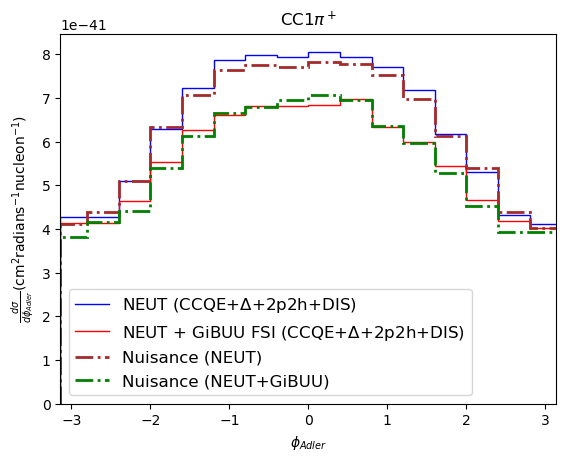

In [95]:
bins_phi=np.array([-3.1415,-2.4000,-2.0000,-1.6000,-1.2000,-0.8000,-0.4000,0.0000,0.4000,0.8000,1.2000,1.6000,2.0000,2.4000,2.8000,3.1415])
bins_costh=np.array([-1.0000,-0.8000,-0.7000,-0.6000,-0.5000,-0.4000,-0.3000,-0.2000,-0.1000,0.0000,0.1000,0.2000,0.3000,0.4000,0.5000,0.6000,0.7000,0.8000,0.9000,1.0000])   	#0.0607
diff=(bins_phi[1:]-bins_phi[:-1])

constant=((len(weight[idx1])+len(weight[targetA==1]))/1e6)**(-1)*weight[idx1][0]### those Q2 within physical range ###

yy_piAdler_h,bins=np.histogram(np.array(AzimuthalAngle_h),bins=bins_phi, weights=weightp[targetA==1][mask_cc1pi1p_mod_h[0]]*constant)
yypiAdler,bins=np.histogram(AzimuthalAngle, bins=bins_phi,weights=weightp[idx1][mask_cc1pi1p_all[0]]*constant)
# plt.step(bins1,np.append(yy/diff,yy[-1]), where="post",  label="NEUT reweighted for Res")
plt.stairs((yypiAdler+yy_piAdler_h)/diff,bins_phi, color="blue", label=r"NEUT (CCQE+$\Delta$+2p2h+DIS)")
zzpiAdler,bins=np.histogram(AzimuthalAngle_g,bins=bins_phi,weights=weightp[idx1][mask_cc1pi_mod_gibuu[0]]*constant)
# plt.step(bins1,np.append(zz/diff,zz[-1]), color="pink", where="post",  label="GiBUU reweighted for Res")
plt.stairs((zzpiAdler+yy_piAdler_h)/diff,bins_phi, color="red",  label=r"NEUT + GiBUU FSI (CCQE+$\Delta$+2p2h+DIS)")
file_test=uproot.open("/data/neutrinos/scratch/pingal/nuisance/build/app/test_adler_phi.root")

plt.stairs(file_test['T2K_CC1pip_CH_XSec_1DAdlerPhi_nu_MC'].values(),file_test['T2K_CC1pip_CH_XSec_1DAdlerPhi_nu_MC'].axis().edges(),color="brown",ls="-.",lw=2,label="Nuisance (NEUT)")

file_test=uproot.open("/data/neutrinos/scratch/pingal/nuisance/build/app/test_adler_phi_gibuu.root")

plt.stairs(file_test['T2K_CC1pip_CH_XSec_1DAdlerPhi_nu_MC'].values(),file_test['T2K_CC1pip_CH_XSec_1DAdlerPhi_nu_MC'].axis().edges(),color="green",ls="-.",lw=2,label="Nuisance (NEUT+GiBUU)")
plt.xlim(-3.14,3.14)
plt.xlabel(r"$\phi_{Adler}$")
plt.ylabel(r"$\frac{d\sigma}{d\phi_{Adler}} (\rm cm^{2} radians^{-1}nucleon^{-1})$")
plt.title(r"CC1$\pi^+$")
plt.legend(fontsize=12)
plt.savefig("CC1pi_phi_adler.png")


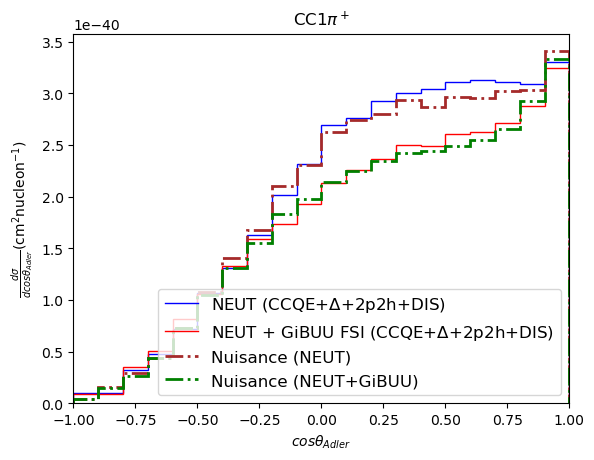

In [96]:
bins_phi=np.array([-3.1415,-2.4000,-2.0000,-1.6000,-1.2000,-0.8000,-0.4000,0.0000,0.4000,0.8000,1.2000,1.6000,2.0000,2.4000,2.8000,3.1415])
bins_costh=np.array([-1.0000,-0.8000,-0.7000,-0.6000,-0.5000,-0.4000,-0.3000,-0.2000,-0.1000,0.0000,0.1000,0.2000,0.3000,0.4000,0.5000,0.6000,0.7000,0.8000,0.9000,1.0000])   	#0.0607
diff=(bins_costh[1:]-bins_costh[:-1])

constant=((len(weight[idx1])+len(weight[targetA==1]))/1e6)**(-1)*weight[idx1][0]### those Q2 within physical range ###

yy_piAdler_h,bins=np.histogram(np.array(AdlerAngle_h),bins=bins_costh, weights=weightp[targetA==1][mask_cc1pi1p_mod_h[0]]*constant)
yypiAdler,bins=np.histogram(AdlerAngle, bins=bins_costh,weights=weightp[idx1][mask_cc1pi1p_all[0]]*constant)
# plt.step(bins1,np.append(yy/diff,yy[-1]), where="post",  label="NEUT reweighted for Res")
plt.stairs((yypiAdler+yy_piAdler_h)/diff,bins_costh, color="blue", label=r"NEUT (CCQE+$\Delta$+2p2h+DIS)")
zzpiAdler,bins=np.histogram(AdlerAngle_g,bins=bins_costh,weights=weightp[idx1][mask_cc1pi_mod_gibuu[0]]*constant)
# plt.step(bins1,np.append(zz/diff,zz[-1]), color="pink", where="post",  label="GiBUU reweighted for Res")
plt.stairs((zzpiAdler+yy_piAdler_h)/diff,bins_costh, color="red",  label=r"NEUT + GiBUU FSI (CCQE+$\Delta$+2p2h+DIS)")
file_test=uproot.open("/data/neutrinos/scratch/pingal/nuisance/build/app/test_adler_theta.root")

plt.stairs(file_test['T2K_CC1pip_CH_XSec_1DCosThAdler_nu_MC'].values(),file_test['T2K_CC1pip_CH_XSec_1DCosThAdler_nu_MC'].axis().edges(),color="brown",ls="-.",lw=2,label="Nuisance (NEUT)")

file_test=uproot.open("/data/neutrinos/scratch/pingal/nuisance/build/app/test_adler_theta_gibuu.root")

plt.stairs(file_test['T2K_CC1pip_CH_XSec_1DCosThAdler_nu_MC'].values(),file_test['T2K_CC1pip_CH_XSec_1DCosThAdler_nu_MC'].axis().edges(),color="green",ls="-.",lw=2,label="Nuisance (NEUT+GiBUU)")
plt.xlim(-1.0,1.0)
plt.xlabel(r"$cos\theta_{Adler}$")
plt.ylabel(r"$\frac{d\sigma}{dcos\theta_{Adler}} (\rm cm^{2} nucleon^{-1})$")
plt.title(r"CC1$\pi^+$")
plt.legend(fontsize=12)
plt.savefig("CC1pi_theta_adler.png")


In [87]:
#### Alll are rough calculations below

In [88]:
yy_piAdler_h,yypiAdler

(array([1.32624268e-43, 3.07848813e-43, 5.82371253e-43, 1.09781159e-42,
        1.84498114e-42, 2.54504511e-42, 3.38698438e-42, 4.26927469e-42,
        4.83238431e-42, 5.79155913e-42, 5.94061356e-42, 5.88749525e-42,
        6.55091471e-42, 5.99139021e-42, 6.43988288e-42, 5.96638749e-42,
        5.60684172e-42, 5.10274475e-42, 4.95295984e-42]),
 <Array [1.82e-42, 2.89e-42, ..., 2.58e-41, 2.81e-41] type='19 * float64'>)

In [89]:
px_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[1]]

<Array [[0.0718], [-0.231], ..., [0.277], [0.106]] type='67054 * var * float64'>

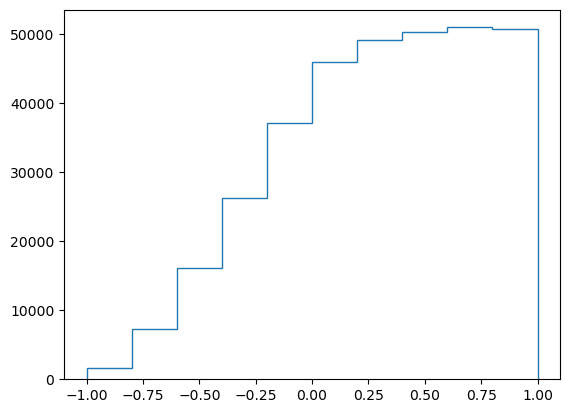

In [90]:
bins_array = np.arange(-1.0,1.20,0.20)
diff=(bins_array[1:]-bins_array[:-1])
hist,bins1=np.histogram(AdlerAngle,bins=bins_array, range=(-1,1))
plt.stairs(hist/diff,bins1)

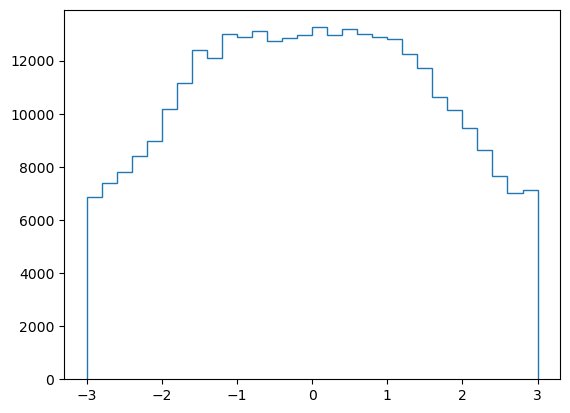

In [91]:
bins_array = np.arange(-3.0,3.20,0.20)
diff=(bins_array[1:]-bins_array[:-1])
hist,bins1=np.histogram(AzimuthalAngle,bins=bins_array, range=(-1,1))
plt.stairs(hist/diff,bins1)

In [92]:
## relativistic boost
def boost(E, p, beta):
    b2 = np.sum(beta**2, axis=1)
    gamma =  1.0 / np.sqrt(1.0 - b2) 
    bp = np.sum(beta * p, axis=1)
    E_new = gamma * (E - bp)
    safe_b2 = np.where(b2 > 0, b2, 1.0)
    coef = np.where(b2 > 0, (gamma - 1.0) / safe_b2, 0.0) * bp - gamma * E
    p_new = p + coef[:, None] * beta
    return E_new, p_new

def rotate_vectors(vectors, angle, axis):
    """
    Rotate N vectors by N angles around N axes.

    vectors : (3, N)
        vectors[:, i] = vector for event i

    angle : (N,)
        angle[i] = rotation angle for event i, in radians

    axis : (3, N)
        axis[:, i] = rotation axis for event i

    Returns
    -------
    rotated : (3, N)
    """

    vectors = np.asarray(vectors, dtype=float)
    angle = np.asarray(angle, dtype=float)
    axis = np.asarray(axis, dtype=float)

    # Normalize each axis independently
    axis_norm = np.linalg.norm(axis, axis=0)
    axis_hat = axis / axis_norm[None, :]

    ax = axis_hat[0]
    ay = axis_hat[1]
    az = axis_hat[2]

    c = np.cos(angle)
    s = np.sin(angle)
    C = 1.0 - c

    # Rodrigues rotation matrix for every event
    R = np.empty((3, 3, vectors.shape[1]))

    R[0, 0] = c + ax * ax * C
    R[0, 1] = ax * ay * C - az * s
    R[0, 2] = ax * az * C + ay * s

    R[1, 0] = ay * ax * C + az * s
    R[1, 1] = c + ay * ay * C
    R[1, 2] = ay * az * C - ax * s

    R[2, 0] = az * ax * C - ay * s
    R[2, 1] = az * ay * C + ax * s
    R[2, 2] = c + az * az * C

    # Apply each event's rotation matrix to its vector
    rotated = np.einsum('ijk,jk->ik', R, vectors)

    return rotated 
def unit(v):
    return v/np.linalg.norm(v,axis=0)


def vel(E,p):
    return np.array([p[:,0]/E,p[:,1]/E,p[:,2]/E])


In [93]:
# px_p_lead=ak.flatten(px_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[3]])
# py_p_lead=ak.flatten(py_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[3]])
# pz_p_lead=ak.flatten(pz_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[3]])
# E_p_lead=ak.flatten(E_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[3]])-0.035
pdg_arr   = pdg[idx1]
chase_arr = chase[idx1]
E_arr     = E[idx1]
Q2_arr = Q2[idx1]
px_arr = px[idx1]
py_arr= py[idx1]
pz_arr= pz[idx1]
mode_arr=mode[idx1]
mass_offset=0.035
enf=truenuE[idx1]

px_pi=ak.flatten(px_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[1]])
py_pi=ak.flatten(py_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[1]])
pz_pi=ak.flatten(pz_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[1]])
E_pi=ak.flatten(E_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[1]])

px_mu=ak.flatten(px_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[2]])
py_mu=ak.flatten(py_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[2]])
pz_mu=ak.flatten(pz_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[2]])
E_mu=ak.flatten(E_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[2]])

px_nu=px_arr[mask_cc1pi1p_all[0]][:,0]
py_nu=py_arr[mask_cc1pi1p_all[0]][:,0]
pz_nu=pz_arr[mask_cc1pi1p_all[0]][:,0]
E_nu=E_arr[mask_cc1pi1p_all[0]][:,0]


px_target=px_arr[mask_cc1pi1p_all[0]][:,1]
py_target=py_arr[mask_cc1pi1p_all[0]][:,1]
pz_target=pz_arr[mask_cc1pi1p_all[0]][:,1]
E_target = np.sqrt(px_target**2 + py_target**2 + pz_target**2 + 0.938**2)
beta_N=to3(
    px_target / E_target,
    py_target / E_target,
    pz_target / E_target
)
beta_N[np.sum(beta_N**2, axis=1)>1]=0.0
p_pi_star=np.array(boost(E_pi,to3(px_pi,py_pi,pz_pi),beta_N)[1])
E_pi_star=np.array(boost(E_pi,to3(px_pi,py_pi,pz_pi),beta_N)[0])


p_mu_star=np.array(boost(E_mu,to3(px_mu,py_mu,pz_mu),beta_N)[1])
E_mu_star=np.array(boost(E_mu,to3(px_mu,py_mu,pz_mu),beta_N)[0])

p_nu_star=np.array(boost(E_nu,to3(px_nu,py_nu,pz_nu),beta_N)[1])
E_nu_star=np.array(boost(E_nu,to3(px_nu,py_nu,pz_nu),beta_N)[0])


p_target_star=np.array(boost(E_target,to3(px_target,py_target,pz_target),beta_N)[1])
E_target_star=np.array(boost(E_target,to3(px_target,py_target,pz_target),beta_N)[0])

# ---------------------------------------------------------------- resonance & q3 in nucleon rest frame
Res  = p_nu_star - p_mu_star + p_target_star          # (N,3)
Res0 = E_nu_star - E_mu_star + E_target_star          # (N,)
Vq3  = np.array(p_nu_star - p_mu_star)                          # (N,3)

N = len(Vq3)
lab = np.array([np.zeros(N), np.zeros(N), np.ones(N)])   # z-axis, (3,N)

# ---------------------------------------------------------------- 1st rotation: q3 -> +z
# axis = q3 x z = (qy, -qx, 0)
axis = np.array([Vq3[:, 1], -Vq3[:, 0], np.zeros(N)])    # (3,N)

# q3 already along +-z: axis is zero -> pick x-axis (angle is 0 or pi, both fine)
deg = np.linalg.norm(axis, axis=0) < 1e-12
axis[:, deg] = np.array([[1.0], [0.0], [0.0]])
axis_unit = unit(axis)

Vq3_unit = unit(Vq3.T)                                   # (3,N)
angle = np.arccos(np.clip(np.sum(lab * Vq3_unit, axis=0), -1.0, 1.0))

v_pi_Adler = rotate_vectors(p_pi_star.T, angle, axis_unit)
v_nu_Adler = rotate_vectors(p_nu_star.T, angle, axis_unit)
v_mu_Adler = rotate_vectors(p_mu_star.T, angle, axis_unit)
res_Adler  = rotate_vectors(Res.T,       angle, axis_unit)

# ---------------------------------------------------------------- 2nd rotation: about z by -phi_nu
phi_nu = np.arctan2(v_nu_Adler[1, :], v_nu_Adler[0, :])

v_pi_Adler2 = rotate_vectors(v_pi_Adler, -phi_nu, lab)   # ROOT: rot2.RotateZ(-phi_nu)
v_nu_Adler2 = rotate_vectors(v_nu_Adler, -phi_nu, lab)   # only for the check below
res_Adler2  = rotate_vectors(res_Adler,  -phi_nu, lab)

# ---------------------------------------------------------------- boost pion to resonance rest frame
beta_res = res_Adler2.T / Res0[:, None]                  # (N,3)
# no clamping: unphysical events (|beta|>=1) become NaN, like ROOT would misbehave
E_pi_A, p_pi_A = boost(E_pi_star, v_pi_Adler2.T, beta_res)

# ---------------------------------------------------------------- angles
Theta_Adler = p_pi_A[:, 2] / np.linalg.norm(p_pi_A, axis=1)   # cos(theta_Adler) = CosTheta()
Phi_Adler   = np.arctan2(p_pi_A[:, 1], p_pi_A[:, 0])          # = Phi()

# ---------------------------------------------------------------- sanity checks (run once)
q3_rot = rotate_vectors(Vq3.T, angle, axis_unit)
print("q3 off-z  :", np.nanmax(np.abs(q3_rot[:2])), "| all +z:", np.all(q3_rot[2] > 0))
print("nu y      :", np.nanmax(np.abs(v_nu_Adler2[1])), "| nu x>=0:", np.all(v_nu_Adler2[0] >= -1e-9))
print("res p RRF :", np.nanmax(np.abs(boost(Res0, res_Adler2.T, beta_res)[1])))
print("NaN events:", np.isnan(Theta_Adler).sum(), "of", N)

q3 off-z  : 2.1350976542322542e-13 | all +z: True
nu y      : 2.6645352591003757e-15 | nu x>=0: True
res p RRF : 7.105427357601002e-15
NaN events: 0 of 67054


In [94]:
# px_p_lead=ak.flatten(px_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[3]])
# py_p_lead=ak.flatten(py_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[3]])
# pz_p_lead=ak.flatten(pz_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[3]])
# E_p_lead=ak.flatten(E_arr[mask_cc1pi1p_all[0]][mask_cc1pi1p_all[3]])-0.035
## 1H
pdg_arr_h   = pdg[targetA==1]
chase_arr_h = chase[targetA==1]
E_arr_h     = E[targetA==1]
Q2_arr_h = Q2[targetA==1]
px_arr_h = px[targetA==1]
py_arr_h= py[targetA==1]
pz_arr_h=pz[targetA==1]
mode_arr_h=mode[targetA==1]
enf_h=truenuE[targetA==1]*np.ones(len(mode[targetA==1]))
p_arr_h=np.sqrt(px_arr_h**2+py_arr_h**2+pz_arr_h**2)
theta_arr_h=np.acos(pz_arr_h/p_arr_h)
mass_offset=0.
mask_cc1pi_mod_h=cc1pi1p_masks(mode_arr_h,pdg_arr_h,Q2_arr_h,chase_arr_h,px_arr_h,py_arr_h,pz_arr_h,E_arr_h,mass_offset)



px_nu=px_arr_h[mask_cc1pi_mod_h[0]][:,0]
py_nu=py_arr_h[mask_cc1pi_mod_h[0]][:,0]
pz_nu=pz_arr_h[mask_cc1pi_mod_h[0]][:,0]
E_nu=E_arr_h[mask_cc1pi_mod_h[0]][:,0]


px_target=px_arr_h[mask_cc1pi_mod_h[0]][:,1]
py_target=py_arr_h[mask_cc1pi_mod_h[0]][:,1]
pz_target=pz_arr_h[mask_cc1pi_mod_h[0]][:,1]
E_target = np.sqrt(px_target**2 + py_target**2 + pz_target**2 + 0.938**2)

px_pi=ak.flatten(px_arr_h[mask_cc1pi_mod_h[0]][mask_cc1pi_mod_h[1]])
py_pi=ak.flatten(py_arr_h[mask_cc1pi_mod_h[0]][mask_cc1pi_mod_h[1]])
pz_pi=ak.flatten(pz_arr_h[mask_cc1pi_mod_h[0]][mask_cc1pi_mod_h[1]])
E_pi=ak.flatten(E_arr_h[mask_cc1pi_mod_h[0]][mask_cc1pi_mod_h[1]])

px_mu=ak.flatten(px_arr_h[mask_cc1pi_mod_h[0]][mask_cc1pi_mod_h[2]])
py_mu=ak.flatten(py_arr_h[mask_cc1pi_mod_h[0]][mask_cc1pi_mod_h[2]])
pz_mu=ak.flatten(pz_arr_h[mask_cc1pi_mod_h[0]][mask_cc1pi_mod_h[2]])
E_mu=ak.flatten(E_arr_h[mask_cc1pi_mod_h[0]][mask_cc1pi_mod_h[2]])


beta_N=to3(
    px_target / E_target,
    py_target / E_target,
    pz_target / E_target
)
beta_N[np.sum(beta_N**2, axis=1)>1]=0.0
p_pi_star=np.array(boost(E_pi,to3(px_pi,py_pi,pz_pi),beta_N)[1])
E_pi_star=np.array(boost(E_pi,to3(px_pi,py_pi,pz_pi),beta_N)[0])


p_mu_star=np.array(boost(E_mu,to3(px_mu,py_mu,pz_mu),beta_N)[1])
E_mu_star=np.array(boost(E_mu,to3(px_mu,py_mu,pz_mu),beta_N)[0])

p_nu_star=np.array(boost(E_nu,to3(px_nu,py_nu,pz_nu),beta_N)[1])
E_nu_star=np.array(boost(E_nu,to3(px_nu,py_nu,pz_nu),beta_N)[0])


p_target_star=np.array(boost(E_target,to3(px_target,py_target,pz_target),beta_N)[1])
E_target_star=np.array(boost(E_target,to3(px_target,py_target,pz_target),beta_N)[0])

# ---------------------------------------------------------------- resonance & q3 in nucleon rest frame
Res  = p_nu_star - p_mu_star + p_target_star          # (N,3)
Res0 = E_nu_star - E_mu_star + E_target_star          # (N,)
Vq3  = np.array(p_nu_star - p_mu_star)                          # (N,3)

N = len(Vq3)
lab = np.array([np.zeros(N), np.zeros(N), np.ones(N)])   # z-axis, (3,N)

# ---------------------------------------------------------------- 1st rotation: q3 -> +z
# axis = q3 x z = (qy, -qx, 0)
axis = np.array([Vq3[:, 1], -Vq3[:, 0], np.zeros(N)])    # (3,N)

# q3 already along +-z: axis is zero -> pick x-axis (angle is 0 or pi, both fine)
deg = np.linalg.norm(axis, axis=0) < 1e-12
axis[:, deg] = np.array([[1.0], [0.0], [0.0]])
axis_unit = unit(axis)

Vq3_unit = unit(Vq3.T)                                   # (3,N)
angle = np.arccos(np.clip(np.sum(lab * Vq3_unit, axis=0), -1.0, 1.0))

v_pi_Adler = rotate_vectors(p_pi_star.T, angle, axis_unit)
v_nu_Adler = rotate_vectors(p_nu_star.T, angle, axis_unit)
v_mu_Adler = rotate_vectors(p_mu_star.T, angle, axis_unit)
res_Adler  = rotate_vectors(Res.T,       angle, axis_unit)

# ---------------------------------------------------------------- 2nd rotation: about z by -phi_nu
phi_nu = np.arctan2(v_nu_Adler[1, :], v_nu_Adler[0, :])

v_pi_Adler2 = rotate_vectors(v_pi_Adler, -phi_nu, lab)   # ROOT: rot2.RotateZ(-phi_nu)
v_nu_Adler2 = rotate_vectors(v_nu_Adler, -phi_nu, lab)   # only for the check below
res_Adler2  = rotate_vectors(res_Adler,  -phi_nu, lab)

# ---------------------------------------------------------------- boost pion to resonance rest frame
beta_res = res_Adler2.T / Res0[:, None]                  # (N,3)
# no clamping: unphysical events (|beta|>=1) become NaN, like ROOT would misbehave
E_pi_A, p_pi_A = boost(E_pi_star, v_pi_Adler2.T, beta_res)

# ---------------------------------------------------------------- angles
Theta_Adler_h = p_pi_A[:, 2] / np.linalg.norm(p_pi_A, axis=1)   # cos(theta_Adler) = CosTheta()
Phi_Adler_h   = np.arctan2(p_pi_A[:, 1], p_pi_A[:, 0])          # = Phi()

q3_rot = rotate_vectors(Vq3.T, angle, axis_unit)
print("q3 off-z  :", np.nanmax(np.abs(q3_rot[:2])), "| all +z:", np.all(q3_rot[2] > 0))
print("nu y      :", np.nanmax(np.abs(v_nu_Adler2[1])), "| nu x>=0:", np.all(v_nu_Adler2[0] >= -1e-9))
print("res p RRF :", np.nanmax(np.abs(boost(Res0, res_Adler2.T, beta_res)[1])))
print("NaN events:", np.isnan(Theta_Adler).sum(), "of", N)

NameError: name 'cc1pi1p_masks' is not defined

In [ ]:
bins_array = np.arange(-1.0,1.20,0.20)
diff=(bins_array[1:]-bins_array[:-1])
mode_cc1pi_neut_h=mode_arr_h[mask_cc1pi_mod_h[0]]
enf_cc1pi_neut_h=enf_h[mask_cc1pi_mod_h[0]]
hist1_h,bins1=np.histogram(Theta_Adler_h[mode_cc1pi_neut_h==1], bins=bins_array)
hist2_h,bins1=np.histogram(Theta_Adler_h[mode_cc1pi_neut_h==2], bins=bins_array)
hist3_h,bins1=np.histogram(Theta_Adler_h[mode_cc1pi_neut_h==26], bins=bins_array)

hist4_h,bins1=np.histogram(Theta_Adler_h[mode_cc1pi_neut_h==11], weights=bspl1(enf_cc1pi_neut_h[mode_cc1pi_neut_h==11]), bins=bins_array)
hist5_h,bins1=np.histogram(Theta_Adler_h[mode_cc1pi_neut_h==12], weights=bspl2(enf_cc1pi_neut_h[mode_cc1pi_neut_h==12]),bins=bins_array)
hist6_h,bins1=np.histogram(Theta_Adler_h[mode_cc1pi_neut_h==13], weights=bspl3(enf_cc1pi_neut_h[mode_cc1pi_neut_h==13]),bins=bins_array)

Theta_Adler_mod_h=(hist1_h+hist2_h+hist3_h+hist4_h+hist5_h+hist6_h)
############################
bins_array = np.arange(-1.0,1.20,0.20)
diff=(bins_array[1:]-bins_array[:-1])
mode_cc1pi_neut=mode_arr[mask_cc1pi1p_all[0]]
enf_cc1pi_neut=enf[mask_cc1pi1p_all[0]]
hist1,bins1=np.histogram(Theta_Adler[mode_cc1pi_neut==1], bins=bins_array)
hist2,bins1=np.histogram(Theta_Adler[mode_cc1pi_neut==2], bins=bins_array)
hist3,bins1=np.histogram(Theta_Adler[mode_cc1pi_neut==26], bins=bins_array)

hist4,bins1=np.histogram(Theta_Adler[mode_cc1pi_neut==11], weights=bspl1(enf_cc1pi_neut[mode_cc1pi_neut==11]), bins=bins_array)
hist5,bins1=np.histogram(Theta_Adler[mode_cc1pi_neut==12], weights=bspl2(enf_cc1pi_neut[mode_cc1pi_neut==12]),bins=bins_array)
hist6,bins1=np.histogram(Theta_Adler[mode_cc1pi_neut==13], weights=bspl3(enf_cc1pi_neut[mode_cc1pi_neut==13]),bins=bins_array)

Theta_Adler_mod_h=(hist1_h+hist2_h+hist3_h+hist4_h+hist5_h+hist6_h)
Theta_Adler_mod=(hist1+hist2+hist3+hist4+hist5+hist6)

#constant=weight[idx1][0]*(1000000/(np.size(weight[idx1])+np.sum(targetA==1)))
plt.stairs((Theta_Adler_mod*constant+Theta_Adler_mod_h*weight[idx1][0])/diff,bins1)
plt.ylabel(r"$\frac{d\sigma}{dcos\theta_{Adler}} (\rm cm^{2} nucleon^{-1})$")
plt.xlabel(r"$cos \theta_{Adler}$")

In [ ]:
hist

In [ ]:
bins_array = np.arange(-3.0,3.20,0.20)
diff=(bins_array[1:]-bins_array[:-1])
mode_cc1pi_neut_h=mode_arr_h[mask_cc1pi_mod_h[0]]
enf_cc1pi_neut_h=enf_h[mask_cc1pi_mod_h[0]]
hist1_h,bins1=np.histogram(Phi_Adler_h[mode_cc1pi_neut_h==1], bins=bins_array)
hist2_h,bins1=np.histogram(Phi_Adler_h[mode_cc1pi_neut_h==2], bins=bins_array)
hist3_h,bins1=np.histogram(Phi_Adler_h[mode_cc1pi_neut_h==26], bins=bins_array)

hist4_h,bins1=np.histogram(Phi_Adler_h[mode_cc1pi_neut_h==11], weights=bspl1(enf_cc1pi_neut_h[mode_cc1pi_neut_h==11]), bins=bins_array)
hist5_h,bins1=np.histogram(Phi_Adler_h[mode_cc1pi_neut_h==12], weights=bspl2(enf_cc1pi_neut_h[mode_cc1pi_neut_h==12]),bins=bins_array)
hist6_h,bins1=np.histogram(Phi_Adler_h[mode_cc1pi_neut_h==13], weights=bspl3(enf_cc1pi_neut_h[mode_cc1pi_neut_h==13]),bins=bins_array)

Theta_Adler_mod_h=(hist1_h+hist2_h+hist3_h+hist4_h+hist5_h+hist6_h)
############################
bins_array = np.arange(-3.0,3.20,0.20)
diff=(bins_array[1:]-bins_array[:-1])
mode_cc1pi_neut=mode_arr[mask_cc1pi1p_all[0]]
enf_cc1pi_neut=enf[mask_cc1pi1p_all[0]]
hist1,bins1=np.histogram(Phi_Adler[mode_cc1pi_neut==1], bins=bins_array)
hist2,bins1=np.histogram(Phi_Adler[mode_cc1pi_neut==2], bins=bins_array)
hist3,bins1=np.histogram(Phi_Adler[mode_cc1pi_neut==26], bins=bins_array)

hist4,bins1=np.histogram(Phi_Adler[mode_cc1pi_neut==11], weights=bspl1(enf_cc1pi_neut[mode_cc1pi_neut==11]), bins=bins_array)
hist5,bins1=np.histogram(Phi_Adler[mode_cc1pi_neut==12], weights=bspl2(enf_cc1pi_neut[mode_cc1pi_neut==12]),bins=bins_array)
hist6,bins1=np.histogram(Phi_Adler[mode_cc1pi_neut==13], weights=bspl3(enf_cc1pi_neut[mode_cc1pi_neut==13]),bins=bins_array)

Phi_Adler_mod_h=(hist1_h+hist2_h+hist3_h+hist4_h+hist5_h+hist6_h)
Phi_Adler_mod=(hist1+hist2+hist3+hist4+hist5+hist6)

plt.stairs((Phi_Adler_mod*constant+Phi_Adler_mod_h*weight[idx1][0])/diff,bins1)
plt.ylabel(r"$\frac{d\sigma}{d\phi_{Adler}} (\rm cm^{2} nucleon^{-1})$")
plt.xlabel(r"$\phi_{Adler}$")

In [ ]:
# ## rotate the velocity vectors to angle theta
v_pi_Adler=rotate_vectors(np.transpose(p_pi_star), angle, axis_unit)
v_nu_Adler=rotate_vectors(np.transpose(p_nu_star), angle, axis_unit)
v_mu_Adler=rotate_vectors(np.transpose(p_mu_star), angle, axis_unit)
res_Adler=rotate_vectors(np.transpose(Res), angle, axis_unit)

theta_nu=np.arccos(unit(v_nu_Adler)[2,:])
phi_nu=-np.arctan2(unit(v_nu_Adler)[1,:],unit(v_nu_Adler)[0,:])
#########################################
## then rotate the v_pi_Adler again by -phi angle 
#######################second rotation
v_pi_Adler2=rotate_vectors(v_pi_Adler, phi_nu,lab )
# v_pi_Adler2=v_pi_Adler

res_Adler2=rotate_vectors(res_Adler, phi_nu, lab)
# ### now prepare beta_res
beta_res=to3(
    res_Adler2[0,:] / Res0,
    res_Adler2[1,:] / Res0,
    res_Adler2[2,:] / Res0
)
beta_res[np.sum(beta_res**2, axis=1)>1.0]=0.0
pi_mag=np.sqrt(np.array((p_pi_star*p_pi_star)).sum(axis=1))
pi_Adler_boosted=boost(E_pi_star,to3(v_pi_Adler2[0,:],v_pi_Adler2[1,:],v_pi_Adler2[2,:]),beta_res)
# pi_Adler_boosted=res_Adler.T,v_pi_Adler.T
# Theta_Adler=pi_Adler_boosted[1][:,2]/np.sqrt(pi_Adler_boosted[1][:,2]*pi_Adler_boosted[1][:,2]+pi_Adler_boosted[1][:,1]*pi_Adler_boosted[1][:,1]+pi_Adler_boosted[1][:,0]*pi_Adler_boosted[1][:,0])
Theta_Adler=pi_Adler_boosted[1][:,2]/np.sqrt(pi_Adler_boosted[1][:,2]*pi_Adler_boosted[1][:,2]+pi_Adler_boosted[1][:,1]*pi_Adler_boosted[1][:,1]+pi_Adler_boosted[1][:,0]*pi_Adler_boosted[1][:,0])
Phi_Adler=np.arctan2(pi_Adler_boosted[1][:,1],pi_Adler_boosted[1][:,0])

In [ ]:
np.sum(beta_res**2, axis=1)

In [ ]:
bins_array = np.arange(-1.0,1.20,0.20)
diff=(bins_array[1:]-bins_array[:-1])
hist,bins1=np.histogram(Theta_Adler,bins=bins_array, range=(-1,1))
plt.stairs(hist/diff,bins1)
plt.xlabel(r"$cos\theta_{Adler}$")

In [ ]:
bins_array = np.arange(-3.0,3.20,0.20)
diff=(bins_array[1:]-bins_array[:-1])
hist,bins1=np.histogram(Phi_Adler,bins=bins_array, range=(-3,3))
plt.stairs(hist/diff,bins1)
plt.xlabel(r"$\phi_{Adler}$")

In [ ]:
print(np.sum(np.sum(beta_res**2, axis=1) >= 1), np.isnan(np.array(AdlerAngle)).sum())

In [ ]:
np.array(Vq3_unit*Vq3_unit).sum(axis=0),lab,Vq3[:,1]

In [ ]:
np.array(lab*lab).sum(axis=0)

In [ ]:
E_target_star

In [ ]:
beta_N,unit(vel(E_nu_star-E_mu_star,p_nu_star-p_mu_star)).T

In [ ]:
np.unique(np.isnan(E_pi_star))

In [ ]:
vel(E_pi_star,p_pi_star)

In [ ]:
rotate_vectors(Vq3_unit,angle, axis_unit)

In [ ]:
x=np.nan_to_num(unit(vel(E_pi_star,p_pi_star)),0)
(x*x).sum(axis=0)
np.sum((x*x).sum(axis=0))

In [ ]:
res_Adler2[0,:]

In [ ]:
beta_res,beta_N

In [ ]:
np.sqrt(np.array((v_pi_Adler*v_pi_Adler)).sum(axis=0))-np.sqrt(np.array((p_pi_star*p_pi_star)).sum(axis=1))

In [ ]:
(unit(v_nu_Adler)*unit(v_nu_Adler)).sum(axis=0)

In [ ]:
np.transpose(p_pi_star),v_pi_Adler

In [ ]:
np.array((p_pi_star*p_pi_star)).sum(axis=1)

In [ ]:
np.unique(np.isnan(pi_mag))

In [ ]:
# ---------- Adler frame (replaces everything from Vq3 onward) ----------
N = len(E_pi)

# Nucleon-rest-frame momenta as (3, N) float64 arrays
P = lambda a: np.asarray(a, dtype=np.float64).T
pi_s, nu_s, mu_s = P(p_pi_star), P(p_nu_star), P(p_mu_star)
res_s = P(Res)                       # resonance 3-momentum, nucleon frame
Res0  = np.asarray(Res0, dtype=np.float64)
# Res0  = np.asarray(1.232*np.ones(N), dtype=np.float64)

# q3 = p_nu - p_mu (momenta, NOT velocities)
q3 = nu_s -constant=weight[idx1][0]*(1000000/(np.size(weight[idx1])+np.sum(targetA==1)))
 mu_s
q3_hat = unit(q3)

zhat = np.zeros((3, N)); zhat[2] = 1.0

# 1) rotation taking q3 -> z
axis = np.cross(q3.T, zhat.T).T                     # q3 x z, shape (3, N)
angle = np.arccos(np.clip((q3_hat * zhat).sum(axis=0), -1.0, 1.0))

# q3 parallel/antiparallel to z: axis = 0 -> pick x axis (angle is 0 or pi)
degenerate = np.linalg.norm(axis, axis=0) < 1e-12
axis[:, degenerate] = np.array([[1.0], [0.0], [0.0]])
axis_unit = unit(axis)

pi_A  = rotate_vectors(pi_s,  angle, axis_unit)
nu_A  = rotate_vectors(nu_s,  angle, axis_unit)
mu_A  = rotate_vectors(mu_s,  angle, axis_unit)
res_A = rotate_vectors(res_s, angle, axis_unit)

# check: q3 should now point along +z
q3_A = nu_A - mu_A
print("max |qx|,|qy| after rot:", np.abs(q3_A[:2]).max(),
      " all qz>0:", np.all(q3_A[2] > 0))

# 2) rotate about z by -phi_nu so the lepton plane is the x-z plane
phi_nu = np.arctan2(nu_A[1], nu_A[0])               # neutrino azimuth
pi_A   = rotate_vectors(pi_A,  -phi_nu, zhat)
res_A  = rotate_vectors(res_A, -phi_nu, zhat)

# 3) boost pion (nucleon frame) to the resonance rest frame
beta_res = (res_A / Res0).T                         # (N, 3)
E_pi_R, p_pi_R = boost(np.asarray(E_pi_star, dtype=np.float64),
                       pi_A.T, beta_res)
p_pi_R = np.asarray(p_pi_R)

# 4) Adler angles
p_mag = np.linalg.norm(p_pi_R, axis=1)
cosTheta_Adler = p_pi_R[:, 2] / p_mag               # = TLorentzVector::CosTheta()
Phi_Adler      = np.arctan2(p_pi_R[:, 1], p_pi_R[:, 0])

# diagnostics
W2 = Res0**2 - (res_s**2).sum(axis=0)
print("W2<0:", np.sum(W2 < 0), " NaNs:", np.isnan(cosTheta_Adler).sum())

In [ ]:
plt.hist(Theta_Adler,bins=100, range=(-1,1))

In [ ]:
plt.hist(Phi_Adler,bins=100, range=(-3,3))

In [ ]:
test=(Res0*Res0-Res[:,0]*Res[:,0]-Res[:,0]*Res[:,0]-Res[:,0]*Res[:,0])
plt.hist(test,bins=100, range=(0,2))

In [ ]:
vel(E_nu_star-E_mu_star,p_nu_star-p_mu_star).T

In [ ]:
(unit(v_pi_Adler)*unit(v_pi_Adler)).sum(axis=0)


In [ ]:
unit(v_pi_Adler)[2,:]

In [ ]:
v_pi_Adler0

In [ ]:
(axis_unit*axis_unit).sum(axis=0)

In [ ]:
(Vq3_unit*Vq3_unit).sum(axis=0)

In [ ]:
np.linalg.norm(axis,axis=0)

In [ ]:
angle

In [ ]:
unit(axis)

In [ ]:
px_target_star,py_target_star,pz_target_star

In [ ]:
len(cos_th[(cos_th<1) & (-1< cos_th)])

In [ ]:
px_target_star

In [ ]:
bins_array = np.arange(-3.0,3.6,0.60)
diff=(bins_array[1:]-bins_array[:-1])
dphit,binth=np.histogram(phit,bins=bins_array,weights=np.ones(len(cos_th))*constant)
plt.stairs(np.array(dphit/diff),binth)
plt.xlabel(r"$\phi_{Adler}$")

In [ ]:
phit